# Sandbox for QnRL v11 algorithm and model

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt
from sklearn.model_selection import ParameterGrid
import uuid # for hashing

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [7]:
wires = qml.wires.Wires(list(range(4)))
n_layers = 3
layers = list(range(n_layers))
imprimitive_offset_by_layer = tuple((l % (len(wires) - 1)) + 1 for l in range(n_layers))
print(f"{imprimitive_offset_by_layer=}")
for l in layers:
    act_on = [wires.subset([i, i + imprimitive_offset_by_layer[l]], periodic_boundary=True) for i in range(len(wires))]
    print(f"{l}: {act_on}")

imprimitive_offset_by_layer=(1, 2, 3)
0: [Wires([0, 1]), Wires([1, 2]), Wires([2, 3]), Wires([3, 0])]
1: [Wires([0, 2]), Wires([1, 3]), Wires([2, 0]), Wires([3, 1])]
2: [Wires([0, 3]), Wires([1, 0]), Wires([2, 1]), Wires([3, 2])]


In [3]:
import wandb

wandb.login()

wandb: Currently logged in as: zanderman (zanderman-virginia-tech) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [4]:
print(jax.local_device_count())

1


In [5]:
# Create default configuration storage object.
store = qnrl.store.HashStore(path="./hashstore-qnrl-v11.json")

In [6]:
# Show the number of configurations in hash store.
len(store)

26

In [7]:
[1., 1., 1., 1., 4.*jnp.pi, 9.*jnp.pi]

[1.0, 1.0, 1.0, 1.0, 12.566370614359172, 28.274333882308138]

## Model

In [7]:
from dataclasses import dataclass, field
from qnrl.modules import SerializableModule, activation_function_dispatcher
from functools import partial, reduce
from itertools import combinations
from typing import Literal


class PhaseShiftX(qml.operation.Operation):
    """Variation of `qml.PhaseShift` with Pauli X rotation.
    
    This is useful because the same rotation angle `phi` is used for both the Pauli rotation and the global phase operation.
    """
    num_wires = 1
    num_params = 1
    
    @staticmethod
    def compute_decomposition(phi: qml.typing.TensorLike, wires: qml.wires.WiresLike) -> qml.operation.Operator:
        return [qml.RX(phi, wires=wires), qml.GlobalPhase(-phi / 2.)]

class PhaseShiftY(qml.operation.Operation):
    """Variation of `qml.PhaseShift` with Pauli Y rotation.
    
    This is useful because the same rotation angle `phi` is used for both the Pauli rotation and the global phase operation.
    """
    num_wires = 1
    num_params = 1
    
    @staticmethod
    def compute_decomposition(phi: qml.typing.TensorLike, wires: qml.wires.WiresLike) -> qml.operation.Operator:
        return [qml.RY(phi, wires=wires), qml.GlobalPhase(-phi / 2.)]


OP_STRINGS_ONE_QUBIT: dict[str, type[qml.operation.Operation]] = {
    'rx': qml.RX,
    'ry': qml.RY,
    'rz': qml.RZ,
    'globalphase': qml.GlobalPhase,
    'phaseshift': qml.PhaseShift,
    'pz': qml.PhaseShift, # Alias for 'phaseshift'.
    'px': PhaseShiftX,
    'py': PhaseShiftY,
    'rot': qml.Rot,
}
"""Link PennyLane one-qubit (parameterized) operations to string names."""

type OpTypeOneQubit = Literal[*tuple(OP_STRINGS_ONE_QUBIT.keys())]

OP_STRINGS_TWO_QUBIT: dict[str, type[qml.ops.op_math.ControlledOp]] = {
    'cnot': qml.CNOT,
    'cx': qml.CNOT,
    'cy': qml.CY,
    'cz': qml.CZ,
}
"""Link PennyLane two-qubit operations to string names."""

type OpTypeTwoQubit = Literal[*tuple(OP_STRINGS_TWO_QUBIT.keys())]

def get_op_from_string_one_qubit(op: OpTypeOneQubit) -> type[qml.operation.Operation]:
    """Map a one-qubit (parameterized) operation from string name to operation class type."""
    try:
        op_fn = OP_STRINGS_ONE_QUBIT[op.lower()]
        return op_fn
    except:
        raise ValueError(f"Unsupported one-qubit parameterized operation string: {op}")

def get_op_from_string_two_qubit(op: OpTypeTwoQubit) -> type[qml.ops.op_math.ControlledOp]:
    """Map a two-qubit operation from string name to operation class type."""
    try:
        op_fn = OP_STRINGS_TWO_QUBIT[op.lower()]
        return op_fn
    except:
        raise ValueError(f"Unsupported two-qubit operation string: {op}")

def get_op_from_string(op: OpTypeOneQubit) -> type[qml.operation.Operation]:
    """Map a parameterized operation from string name to operation class type."""
    try:
        op_fn = OP_STRINGS_ONE_QUBIT[op.lower()]
        return op_fn
    except:
        raise ValueError(f"Unsupported parameterized operation string: {op}")

def get_op_num_params(op: str) -> int:
    obj = get_op_from_string_one_qubit(op)
    return obj.num_params

def get_ops_num_params(ops: tuple[str,...]) -> int:
    """Get total number of parameters for operations in tuple."""
    return sum(get_op_from_string_one_qubit(op_string).num_params for op_string in ops)

def get_ops_params_shape(wires: list[int], ops: tuple[str,...]):
    num_params = get_ops_num_params(ops)
    num_wires = len(wires)
    return (num_wires, num_params,)





def circuit_layer_ent_neighbor(wires: list[int], op: OpTypeTwoQubit, reverse: bool = False):
    """NExt-neighbor entanglement layer.

    Args:
        wires (list[int]): List of wires.
    """
    op_func = get_op_from_string_two_qubit(op=op)
    
    gen = zip(wires, wires[1:])
    if reverse:
        gen = list(reversed(list(gen)))
    for w0, w1 in gen:
        op_func(wires=[w0, w1]) # Control w0, target w1.


def circuit_layer_ent_circ(wires: list[int], op: OpTypeTwoQubit):
    """Circular entanglement layer.

    Args:
        wires (list[int]): List of wires.
    """
    op_func = get_op_from_string_two_qubit(op=op)
    
    for w0, w1 in zip(wires, wires[1:]):
        op_func(wires=[w0, w1]) # Control w0, target w1.
    if len(wires) != 2:
        op_func(wires=[wires[-1], wires[0]]) # Control w[-1], target w[0].


def circuit_layer_ent_circ_offset(wires: list[int], imprimitive_offset: int, op: OpTypeTwoQubit):
    """Circular entanglement that is governed by an offset index, defining which qubits are entangled (with circular rollover).

    Args:
        wires (list[int]): List of wires.
    """
    op_func = get_op_from_string_two_qubit(op=op)
    
    wires = qml.wires.Wires(wires)
    for i in range(len(wires)):
        act_on = wires.subset([i, i + imprimitive_offset], periodic_boundary=True)
        op_func(wires=act_on)

# def circuit_layer_enc(phi: jax.Array, wires: list[int]):
#     """Encoding layer using `RX`.

#     Args:
#         phi (jax.Array): Encoding parameters for the layer of shape `(num_wires,1)`.
#         wires (list[int]): _description_
#     """
#     for w in wires:
#         # ## Original
#         # qml.RX(phi=phi[w,0], wires=w)
#         ####
#         qml.Hadamard(wires=w)
#         qml.PhaseShift(phi=2*phi[w,0], wires=w)

def circuit_layer_enc(phi: jax.Array, wires: list[int], pauli: tuple[str, ...] = ('Z',)):
    """Encoding layer using Pauli feature map.

    Args:
        phi (jax.Array): Encoding parameters for the layer of shape `(num_wires,1)`.
        wires (list[int]): _description_
    """
    
    def basis_change(wire_tup: tuple[int, ...], pauli_tup: tuple[str, ...], inverse: bool = False):
        assert len(wire_tup) == len(pauli_tup), "number of wires must match length of Pauli string"
        ## Basis change.
        # Iterate over every wire in the n-pair, and match it with associate Pauli.
        for w, p in zip(wire_tup, pauli_tup):
            match (p, inverse):
                case ('x', _):
                    qml.Hadamard(wires=w)
                case ('y', False):
                    qml.SX(wires=w)
                case ('y', True):
                    qml.adjoint(qml.SX(wires=w))
    
    def cx_chain(wire_tup: tuple[int, ...], inverse: bool = False):
        ## CNOT chain.
        # Pair items in the tuple in groups of 2.
        gen = range(len(wire_tup) - 1)
        if inverse:
            gen = reversed(gen)
        for i in gen:
            qml.CNOT(wires=[wire_tup[i], wire_tup[i+1]])
    
    # print(f"circuit_layer_enc: {phi.shape = }")
    # jax.debug.print("circuit_layer_enc: {}", phi)
    for f, pauli_string in enumerate(pauli): # (feature_index, pauli_string)
        match pauli_string.lower():
            case 'rx':
                for w in wires:
                    qml.RX(phi=phi[w,f], wires=w)
            case 'ry':
                for w in wires:
                    qml.RY(phi=phi[w,f], wires=w)
            case 'rz':
                for w in wires:
                    qml.RZ(phi=phi[w,f], wires=w)
            case _:
                # Apply Hadamard on every qubit.
                for w in wires:
                    qml.Hadamard(wires=w)
                
                # Collect the individual Pauli operators of the current Pauli string chain.
                # Reverse the order for correct qubit assignment (i.e., [p2,p1,p0][::-1] -> [q0,q1,q2]).
                pauli_tup = tuple(pauli_string.lower()[::-1])
                # Iterate over all n-pairs of wires.
                wire_pairs = list(combinations(wires, len(pauli_tup)))
                for wire_tup in wire_pairs:
                    ## Basis change.
                    basis_change(wire_tup=wire_tup, pauli_tup=pauli_tup, inverse=False)
                    ## CNOT chain.
                    cx_chain(wire_tup=wire_tup, inverse=False)
                    ## Phase gate at last qubit in the tuple chain.
                    # Rotation angle is only a single parameter.
                    if len(wire_tup) == 1:
                        angle = phi[wire_tup[-1],f]
                    # Rotation angle is a difference of multiple parameters in the Pauli chain.
                    else:
                        angle = reduce(lambda a, b: a * b, jnp.pi - phi[wire_tup,f])
                    # # Multiply angle by 2.
                    # angle = angle * 2.
                    # Apply phase shift using custom rotation angle.
                    qml.PhaseShift(phi=angle, wires=wire_tup[-1])
                    ## CNOT chain.
                    cx_chain(wire_tup=wire_tup, inverse=True)
                    ## Basis change.
                    basis_change(wire_tup=wire_tup, pauli_tup=pauli_tup, inverse=True)


def circuit_layer_op(phi: jax.Array, wires: list[int], pauli: tuple[str,...]):
    """Operational layer `U |psi>`.

    Args:
        phi (jax.Array): Variational parameters for the layer of shape `(num_wires,len(pauli),)`.
        wires (list[int]): List of wires.
    """
    param_idx = 0
    for op_str in pauli:
        op_num_params = get_op_num_params(op_str)
        op_fn = get_op_from_string(op_str)
        idx_offset = param_idx + op_num_params
        idx_slice = slice(param_idx, idx_offset)
        for i, w in enumerate(wires):
            op_fn(*phi[i,idx_slice], wires=w)
        param_idx = idx_offset

def circuit_layer_reset(wires: list[int]):
    """Measure the given qubits to collapse their state, then reset to zero."""
    for w in wires:
        qml.measure(wires=w, reset=True)

def get_ops_for_returns_distribution(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_layers+1, d_returns, 3,)
    n_layers: int,
    wires: list[int],
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Return-atom distribution unitary.
    
    Generates a return distribuion encoded on the given wires.
    
    The schema of this operation is:
        - `n_layers+1` Variational layers
        - `n_layers` Circular-entanglement layers
        - `n_layers` Input encoding layers
    """
    
    imprimitive_offset_by_layer = tuple((l % (len(wires) - 1)) + 1 for l in range(n_layers))
    
    imprimitive_type = None
    if imprimitive is not None and "-" in imprimitive:
        imprimitive_type, imprimitive = imprimitive.split("-")
    
    for l in range(n_layers):
        
        # Encoder as a function of the layer number.
        circuit_layer_op(phi=inputs[l], wires=wires, pauli=pauli_enc)
        
        # Entangle.
        if imprimitive is not None:
            
            match imprimitive_type:
                case "circ" | None: # Defaults to circular entanglement.
                    circuit_layer_ent_circ(wires=wires, op=imprimitive)
                case "offset":
                    circuit_layer_ent_circ_offset(wires=wires, op=imprimitive, imprimitive_offset=imprimitive_offset_by_layer[l])
                case _:
                    raise ValueError(f"Unsupported imprimitive type: {imprimitive_type}")
        
        # Variation.
        circuit_layer_op(phi=weights[l], wires=wires, pauli=pauli_var)


def prepare_m_moment(
    m_moment: int,
    U_atoms: jax.Array,
    wires_returns: list[int],
    ):
    """Prepare m-th moment of the return distribuion encoded onto the given wires."""
    # Apply the (non-unitary) return-atom-value operation.
    for _ in range(m_moment):
        qml.QubitUnitary(U_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.

def prepare_returns_probability_distribution(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    n_layers: int,
    wires_actions: list[int],
    wires_returns: list[int],
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Prepare return probability distribuion for every action."""
    ###
    # Generate unique return-atom distribution for every action.
    ###
    ops = [
        qml.prod(get_ops_for_returns_distribution)(
            inputs=inputs[a],
            weights=weights[a],
            n_layers=n_layers,
            wires=wires_returns,
            pauli_enc=pauli_enc,
            pauli_var=pauli_var,
            imprimitive=imprimitive,
        )
        for a in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)
    
    ###
    # Apply operations on all action-return distributions.
    ###
    # Quantum Fourier Transform.
    qml.QFT(wires=wires_returns)

def circuit_action_dist(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Quantum circuit for estimating the action distribution via m-th moment of return distribuion followed by amplitude kickback trick with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )
    # Prepare the m-th moment of the returns distribution.
    prepare_m_moment(
        m_moment=m_moment,
        U_atoms=U_atoms,
        wires_returns=wiredict['returns'],
    )
    # Measure the return-atom qubits to collapse their state, then reset to zero.
    circuit_layer_reset(wires=wiredict['returns'])
    
    # Generate action distribuion via measurements across the action wires.
    return qml.probs(wires=wiredict['actions'])

def circuit_return_dist(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )
    
    # Generate weighted return distribuion via measurements across the return wires.
    return qml.probs(wires=wiredict['returns'])

def circuit_return_dist_shifted(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns, 2**d_returns)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )
    
    # Redistribute shifted return-atoms to align with original PMF atoms.
    qml.QubitUnitary(U_shift, wires=wiredict['returns'], unitary_check=False) # We know it's not unitary, so don't check.
    
    # Generate weighted return distribuion via measurements across the return wires.
    return qml.probs(wires=wiredict['returns'])

# TODO Input environment observation must pass through an ML layer to project the observations into a space ingestible for the quantum circuit.
def circuit_hermitian_loss(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )
    
    # Measure the expectation of the return-atom wires w.r.t. a given Hermitian operator.
    H = qml.Hermitian(rho, wires=wiredict['returns']) # Return-atom wires.
    # H = qml.Hermitian(rho, wires=wirelist) # All wires.
    return qml.expval(H)

def circuit_return_density_matrix(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    qml.Snapshot('after_action_prep', measurement=qml.density_matrix(wires=wirelist))
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )
    
    qml.Snapshot('after_return_prep', measurement=qml.density_matrix(wires=wirelist))
    
    # Density matrix for return-atom wires.
    return qml.density_matrix(wires=wiredict['returns'])
    # # Density matrix for all wires.
    # return qml.density_matrix(wires=wirelist)

def circuit_return_density_matrix_shifted(
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns, 2**d_returns)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )
    
    # Redistribute shifted return-atoms to align with original PMF atoms.
    qml.QubitUnitary(U_shift, wires=wiredict['returns'], unitary_check=False) # We know it's not unitary, so don't check.
    
    # Density matrix for return-atom wires.
    return qml.density_matrix(wires=wiredict['returns'])
    # # Density matrix for all wires.
    # return qml.density_matrix(wires=wirelist)

# @partial(nnx.vmap, in_axes=(0,None,None,None,0,None,0,None,None,None,None,None,None))
# 
@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'm_moment',
    'n_layers',
    'U_atoms',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def run_circuit_action_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_action_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_action_dist, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        m_moment=m_moment,
        n_layers=n_layers,
        U_atoms=U_atoms,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'm_moment',
    'n_layers',
    'U_atoms',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def batched_run_circuit_action_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_action_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_action_dist, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # m_moment
            None, # n_layers
            None, # U_atoms
            None, # pauli_enc
            None, # pauli_var
            None, # imprimitive
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        m_moment,
        n_layers,
        U_atoms,
        pauli_enc,
        pauli_var,
        imprimitive,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def run_circuit_return_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_dist, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def batched_run_circuit_return_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_dist, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            None, # imprimitive
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
        imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def run_circuit_return_dist_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_dist_shifted, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        U_shift=U_shift,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def batched_run_circuit_return_dist_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_dist_shifted, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            0, # U_shift
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            None, # imprimitive
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        U_shift,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
        imprimitive,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def run_circuit_hermitian_loss(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_hermitian_loss` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_hermitian_loss, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        rho=rho,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def batched_run_circuit_hermitian_loss(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_hermitian_loss` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_hermitian_loss, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            0, # rho
            None, # pauli_enc
            None, # pauli_var
            None, # imprimitive
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        rho,
        pauli_enc,
        pauli_var,
        imprimitive,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def run_circuit_return_density_matrix(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_density_matrix` on a single of input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_density_matrix, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def batched_run_circuit_return_density_matrix(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_density_matrix` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_density_matrix, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            None, # imprimitive
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
        imprimitive,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def run_circuit_return_density_matrix_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_density_matrix_shifted` on a single of input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_density_matrix_shifted, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        U_shift=U_shift,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        pauli_enc=pauli_enc,
        pauli_var=pauli_var,
        imprimitive=imprimitive,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
    'pauli_enc',
    'pauli_var',
    'imprimitive',
])
def batched_run_circuit_return_density_matrix_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_actions, n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers+1, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    pauli_enc: tuple[str, ...],
    pauli_var: tuple[str, ...],
    imprimitive: str | None, # Entanglement gate string.
    ):
    """Run `circuit_return_density_matrix_shifted` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_density_matrix_shifted, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            0, # U_shift
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            None, # pauli_enc
            None, # pauli_var
            None, # imprimitive
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        U_shift,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        pauli_enc,
        pauli_var,
        imprimitive,
    )



@dataclass(kw_only=True)
class QuantumNativeQNetworkSplit_v11(SerializableModule):
    """Split variant of quantum-native (distributional) Q-value network.
    
    Includes the following splits:
    1. Cascaded amplitude kickback circuit for action probability estimation to prevent memory explosion for high values of `n_reuploads` (with `diffmethod=None` and `shots>0`).
    2. Return distribuion generation and weighted return estimation circuit that ingests the action distribuion from #1 (with `diffmethod='backprop'` and `shots=None`).
    """
    din: int
    """Dimension of input data. The model will map this dimension into one that is supported by the number of return-atom qubits."""
    n_actions: int
    """Number of actions (will require `ceil(log2(n))` qubits)."""
    n_returns: int
    """Number of return atoms (will require `ceil(log2(n))` qubits)."""
    z_min: float
    """Lower bound for return value."""
    z_max: float
    """Upper bound for return value."""
    m_moment: int
    """m-th moment of the return atoms distribution (`E[Z^m]`)."""
    n_reuploads: int
    """n-th power of the expectation over the return atoms distribution (`E[Z]^n`)."""
    n_layers: int
    """Number of re-upload layers to use for the return-atom distribution unitary."""
    rngs_kwargs: dict[str, int]
    pauli_enc: tuple[str, ...]
    """List of Pauli operator strings for encoding layer (e.g., 'X', 'Y', 'Z', 'RX', 'RY', 'RZ')."""
    pauli_var: tuple[str, ...]
    """List of Pauli operator strings for variational layer (e.g., 'X', 'Y', 'Z', 'RX', 'RY', 'RZ')."""
    imprimitive: str | None
    """Entanglement gate string (e.g., 'CNOT', 'CX', 'CZ')."""
    """Number of circuit shots used to compute action probability distribution."""
    input_preprocess: SerializableModule | None = None
    """Nested module for input preprocessing (can be trainable). We need this because the `QuantumNativeQNetworkSplit` class has methods required by the QnRL training algorithm, hence it cannot be wrapped inside another module. To support customizing input preprocessing on a per-environment basis we allow a nested input preprocessing layer to be a member of the `QuantumNativeQNetworkSplit` module."""
    input_multiplex_activation: str = 'linear'
    """Activation function to use after multiplexing input for quantum circuit. Must be a string key contained within the `qnrl.modules.serializable.activation_function_dispatcher` dictionary."""
    
    def __post_init__(self):
        self.rngs: nnx.Rngs = nnx.Rngs(**self.rngs_kwargs)
        
        # Compute qubit count based on number of policies, actions, and return atoms.
        self.d_actions = int(jnp.ceil(jnp.log2(self.n_actions))) # Qubit count for actions.
        self.d_returns = int(jnp.ceil(jnp.log2(self.n_returns))) # Qubit count for return atoms.
        
        # Collect indices of actions based on the total number of actions that can be represented by the number of qubits on the action register.
        self.all_action_idx = list(range(2**self.d_actions)) # All actions represented in the action qubit register.
        self.active_action_idx = list(range(self.n_actions)) # Indices of actions that are being used on the action qubit register.
        self.inactive_action_idx = list(set(self.all_action_idx) - set(self.active_action_idx)) # Indices of actions that are not being used on the action qubit register.
        
        # Collect indices of returns based on the total number of returns that can be represented by the number of qubits on the return register.
        self.all_return_idx = list(range(2**self.d_returns)) # All returns represented in the return qubit register.
        self.active_return_idx = list(range(self.n_returns)) # Indices of returns that are being used on the return qubit register.
        self.inactive_return_idx = list(set(self.all_return_idx) - set(self.active_return_idx)) # Indices of returns that are not being used on the return qubit register.
        
        # Create list of return atoms.
        self.atoms = jnp.array(np.linspace(start=self.z_min, stop=self.z_max, num=self.n_returns))
        # Create non-linear trace non-increasing Kraus matrix of returns atoms.
        atoms_values = self.atoms
        atoms_values = atoms_values - atoms_values.min() # Start from zero.
        atoms_values = atoms_values / atoms_values.sum() # Normalize to probability distribution.
        atoms_values = jnp.sqrt(atoms_values) # Ensure that L2-norm of quantum state amplitude will produce the atom probability (i.e., $|amp|^2 = prob$).
        # Pad with zeros if return atoms shape is not a power of 2.
        if self.n_returns != 2**self.d_returns:
            atoms_values = jnp.pad(atoms_values, (0,2**self.d_returns - self.n_returns), mode='constant')
        # Create quantum operator from the atom values.
        self.U_atoms = jnp.diag(atoms_values)
        
        # Weights for return-atom distribution generation.
        # Every action gets their own return-atom distribution unitary.
        num_var_params = get_ops_num_params(ops=self.pauli_var)
        self.circ_weights_var_shape = (self.n_actions,self.n_layers,self.d_returns,num_var_params,) # Each qubit has (Rz, Ry, Rz).
        self.circ_weights_var = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0., maxval=jnp.pi))
        
        # Inputs to circuit will be encoded onto the return-atom wires.
        num_enc_params = get_ops_num_params(ops=self.pauli_enc)
        self.circ_weights_enc_obs_shape = (self.n_actions,self.n_layers,self.d_returns,num_enc_params,)
        self.circ_weights_enc_obs_kernel = nnx.Param(nnx.initializers.ones_init()(key=self.rngs.params(), shape=self.circ_weights_enc_obs_shape)) # w
        # self.circ_weights_enc_obs_bias = nnx.Param(nnx.initializers.zeros_init()(key=self.rngs.params(), shape=self.circ_weights_enc_obs_shape)) # b
        self.circ_observation_shape_in = self.din # Input dimension of the 
        self.circ_observation_shape_out = (self.n_actions,self.d_returns,num_enc_params,)
        
        # Projects input dimension to dimension supported by quantum circuit.
        self.linear_input_projection = nnx.Linear(in_features=self.din, out_features=reduce(lambda x,y: x*y, self.circ_observation_shape_out), rngs=self.rngs, param_dtype='float64')
        
        # Ensure input multiplex activation string key is valid.
        assert self.input_multiplex_activation in activation_function_dispatcher, f"Invalid activation function key {self.input_multiplex_activation}"
        
    
    @nnx.jit
    def __call__(self, x): # (batch,din,)
        return self.call_gen_action_dist(x) # Generation action distribution.
    
    @nnx.jit
    def project_observations(self, observations: jax.Array): # (batch,din,)
        x = observations
        # Preprocess input data.
        if self.input_preprocess is not None:
            x = self.input_preprocess(x)
        # Project input data into dimension required for quantum circuit.
        x = self.linear_input_projection(x)
        x = jnp.reshape(x, (-1, *self.circ_observation_shape_out,))
        # Multiplex the encoded observations across the layers of each action operator.
        # Einsum dimension labels:
        #   b = batch
        #   l = layer
        #   q = qubit
        #   f = feature
        x = jnp.einsum("alqf,baqf->balqf", self.circ_weights_enc_obs_kernel, x)
        # Pass multiplex result through activation function.
        x = activation_function_dispatcher[self.input_multiplex_activation](x)
        return x
    
    @nnx.jit(static_argnames=['n_reuploads'])
    def call_gen_action_dist(self, x, n_reuploads: int | None = None): # (batch,din,)
        """Generate action distribuion from input observation."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Prepare the n-th power of the m-th moment of the returns distribution.
        key = self.rngs.default() # Generate new random key for circuit measurement.
        # Initially set all actions to equal probability (here all have magnitude of 1, which will be normalized within the quantum circuit code later).
        probs_actions = jnp.ones(shape=(batch_size, self.n_actions,), dtype='float64')
        if n_reuploads is None:
            n_reuploads = self.n_reuploads
        # Create a batch of keys.
        subkeys = [key]
        for _ in range(n_reuploads):
            # Create a batch of keys for the current reupload.
            subkeys = jax.random.split(key=subkeys[0], num=batch_size)
            # Run the circuit on batched input.
            probs_actions = batched_run_circuit_action_dist( # (batch,2**d_actions,)
                # All device and QNode parameters.
                key=subkeys,
                device_name="default.qubit",
                shots=None,
                diff_method=None,
                # Circuit arguments.
                inputs=observation_proj_batched,
                probs_actions=probs_actions,
                weights=self.circ_weights_var,
                n_actions=self.n_actions,
                d_actions=self.d_actions,
                d_returns=self.d_returns,
                m_moment=self.m_moment,
                n_layers=self.n_layers,
                U_atoms=self.U_atoms,
                pauli_enc=self.pauli_enc,
                pauli_var=self.pauli_var,
                imprimitive=self.imprimitive,
            )
            # Filter circuit output based on number of "active" actions.
            # If desired number of actions is not a multiple of 2, then filter out the excess actions on the qubit register (i.e., more actions can be represented on the register and we don't care about them).
            probs_actions = probs_actions[:,jnp.array(self.active_action_idx, dtype=int)] # (batch,n_actions,)
            # Ensure probabilities are normalized after the filter.
            probs_actions = probs_actions / probs_actions.sum(axis=-1, keepdims=True)
        return probs_actions
    
    @nnx.jit
    def call_gen_return_dist(self, x, probs_actions): # (batch,din,)
        """Generate return distribuion from input observation."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            device_name='default.qubit',
            shots=None,
            diff_method='backprop',
            #
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
            imprimitive=self.imprimitive,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        return probs_returns
    
    @nnx.jit
    def call_gen_return_dist_shifted(self, x, probs_actions, U_shift): # (batch,din,)
        """Generate shifted return distribuion from input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist_shifted( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            device_name='default.mixed',
            shots=None,
            diff_method='backprop',
            #
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            U_shift=U_shift,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
            imprimitive=self.imprimitive,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        return probs_returns
    
    
    @nnx.jit
    def call_hermitian_loss(self, x, probs_actions, rho): # (batch,din,)
        """Compute Hermitian loss across the return-atom qubits with respect to an input density matrix rho."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        loss = batched_run_circuit_hermitian_loss( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            device_name="default.qubit",
            shots=None,
            diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            rho=rho,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
            imprimitive=self.imprimitive,
        )
        return loss
    
    @nnx.jit
    def call_return_density_matrix(self, x, probs_actions): # (batch,din,)
        """Generate the density matrix across the return-atom qubits according to an input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        rho = batched_run_circuit_return_density_matrix( # (batch,2**d_returns,2**d_returns)
            # All device and QNode parameters.
            key=subkeys,
            device_name="default.qubit", # Use mixed state simulation for density matrix.
            shots=None,
            diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
            imprimitive=self.imprimitive,
        )
        return rho
    
    @nnx.jit
    def call_return_density_matrix_shifted(self, x, probs_actions, U_shift): # (batch,din,)
        """Generate the shifted density matrix across the return-atom qubits according to an input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        rho = batched_run_circuit_return_density_matrix_shifted( # (batch,2**d_returns,2**d_returns)
            # All device and QNode parameters.
            key=subkeys,
            device_name="default.qubit", # Use mixed state simulation for density matrix.
            shots=None,
            diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            U_shift=U_shift,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            pauli_enc=self.pauli_enc,
            pauli_var=self.pauli_var,
            imprimitive=self.imprimitive,
        )
        return rho

In [8]:
ale_environments = [
    env_spec.id 
    for env_spec in gym.envs.registry.values() 
    if env_spec.id.startswith('ALE/')
]

## Config

In [ ]:

# # Load config from file.
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-13.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-12.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-11.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-10.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-9.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-8.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-7.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-6.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-5.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-0.py")
# module = qnrl.tools.load_python_module_from_filepath(cfg_path)
# config = module.config

# from qnrl.algorithms.qnrl_v2 import QnRL_v2
from qnrl.optimizer import *
from qnrl.environment import *
from qnrl.modules import *

from qnrl.algorithms.qnrl import QnRL

import ale_py
gym.register_envs(ale_py)

from gymnasium.envs.toy_text.cliffwalking import CliffWalkingEnv

# CartPole-v1
din = 4
n_actions = 2
env_id = "CartPole-v1"
env = EnvConfig(env_id=env_id)
z_min = -100
z_max = 100
####
# z_min = 0
# z_max = 500
####
# input_projection_douts = [16,8]
# input_projection_douts = [60,42]
# total_timesteps = 50_000
total_timesteps = 100_000
####
input_preprocess = RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]) # Divide by half the upper range to re-scale.
# n_layers = 3
n_layers = 5

# FrozenLake-v1
env_id = "FrozenLake-v1"
# din = 1
# din = 2
din = 16 # Size of observation space.
n_actions = 4
# env = EnvConfig(env_id=env_id)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id), axis=0)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(2,-1,-0.01))), axis=0)
env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(1.0,-0.2,-0.01), map_name="4x4"), max_episode_steps=100)) # See reward schedule from https://ieeexplore.ieee.org/document/9144562
# env = ObservationDiscreteUnravel(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(1.0,-0.2,-0.01), map_name="4x4"), max_episode_steps=100), shape=(4,4)) # See reward schedule from https://ieeexplore.ieee.org/document/9144562
# z_min = -2
# z_max = 1
###
# z_min = -10
# z_max = 10
###
z_min = -2
z_max = 2
###
total_timesteps = 100_000
input_preprocess = None
n_layers = 5


# CliffWalking-v1
env_id = "CliffWalking-v1"
# din = 1
n_actions = 4
####
# env = EnvConfig(env_id=env_id)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id, max_episode_steps=99), axis=0)
###
# din = 48 # Size of observation space.
# env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, max_episode_steps=99))
# input_preprocess = None
###
din = 2
env = ObservationDiscreteUnravel(env=EnvConfig(env_id=env_id, max_episode_steps=99), shape=(4,12))
input_preprocess = RescaleInput(scale=[4., 12.]) # Grid coordinate into [0, 1].
z_min = -100
z_max = 100
total_timesteps = 100_000
n_layers = 5
# n_layers = 3

# # MountainCar.
# env_id = "MountainCar-v0"
# din = 2
# n_actions = 3
# env = EnvConfig(env_id=env_id)
# total_timesteps = 100_000
# z_min = -100
# z_max = 100
# ###
# # z_min = -200
# # z_max = -1
# input_preprocess = RescaleInput(scale=[1.2, 0.07]) # Divide by the upper range to re-scale to range [-1, 1].
# n_layers = 5

# Acrobot-v1
env_id = "Acrobot-v1"
env = EnvConfig(env_id=env_id)
din = 6
n_actions = 3
z_min = -100
z_max = 100
###
# z_min = -500
# z_max = -1
###
total_timesteps = 100_000
# input_preprocess = None
# input_preprocess = RescaleInput(scale=[0.5, 0.5, 0.5, 0.5, 4.*jnp.pi/2., 9.*jnp.pi/2.]) # Divide by half the upper range to re-scale.
input_preprocess = RescaleInput(scale=[1., 1., 1., 1., 4.*jnp.pi, 9.*jnp.pi]) # Divide by the upper range to re-scale to range [-1, 1].
n_layers = 5
# n_layers = 7


# # ALE/Asteroids-v5
# env_id = "ALE/Asteroids-v5"
# din = 128
# n_actions = 14
# env = EnvConfig(env_id=env_id, extra_args=dict(obs_type="ram", frameskip=1)) # No frame skip.
# z_min = 0
# z_max = 500
# n_layers = 5
# total_timesteps = 100_000
# input_preprocess = RescaleInput(scale=[255.]*din) # Divide by the upper range to re-scale to range [-1, 1].

# n_returns = 101
# n_returns = 2**7 # 128
n_returns = 2**5 # 32

m_moment = 1
# m_moment = 2
# m_moment = 10
# n_reuploads = 1
# n_reuploads = 2
# n_reuploads = 4
n_reuploads = n_actions
# n_reuploads = 5
# n_reuploads = 10
# n_layers = 1
# n_layers = 2
# n_layers = 3
# n_layers = 5
# n_layers = 7
# n_layers = 9
# n_layers = 10
# n_layers = 15

# diff_method=None
# shots=None

# seed = 0
seed = 21
# seed = 42
# seed = 73
# seed = 96

batch_size = 128

# Experiment configuration.
config = QnRL(
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    total_timesteps=total_timesteps,
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    env=env,
    #
    model=QuantumNativeQNetworkSplit_v11(
        din=din,
        n_actions=n_actions,
        n_returns=n_returns,
        z_min=z_min,
        z_max=z_max,
        m_moment=m_moment,
        n_reuploads=n_reuploads,
        n_layers=n_layers,
        # diff_method=diff_method,
        # shots=shots,
        rngs_kwargs=dict(default=seed),
        # pauli=('Z','Y',),
        # pauli=('X',),
        ###
        # pauli_enc=('Z',),
        pauli_enc=('RX',), # Works.
        # pauli_enc=('RX','RY',),
        # pauli_enc=('RX','RZ',),
        # pauli_enc=('RX','RZ','RX'),
        # pauli_enc=('PX',),
        # pauli_enc=('RZ',),
        # pauli_enc=('RZ','RY','RZ',),
        # pauli_enc=('PhaseShift',),
        # pauli_enc=('PhaseShift','RX','PhaseShift',),
        # pauli_enc=('RZ','RX','RZ',), # Works.
        # pauli_enc=('RX','RY','RX',),
        # pauli_enc=('RX','RZ','RX',), # Works.
        # pauli_enc=('RX','RY','RX','GlobalPhase',),
        # pauli_enc=('RX','RY','RX',),
        # pauli_enc=('PhaseShift','Rot','PhaseShift',),
        # pauli_enc=('PhaseShift','RX','Rot',),
        # pauli_enc=('RZ','RX','PhaseShift',),
        # pauli_enc=('PhaseShift','RY','PhaseShift',),
        # pauli_enc=('RY',),
        # pauli_enc=('Z','XX',),
        # pauli_enc=('ZY',),
        # pauli_enc=('RZ',),
        # pauli_enc=('RZ','RY','RZ',),
        # pauli_enc=('RX','RZ','RX',),
        ###
        pauli_var=('RZ','RY','RZ',),
        # pauli_var=('RZ','RY','RZ','GlobalPhase',),
        # pauli_var=('RZ','RY','RZ',),
        # pauli_var=('Rot',),
        # pauli_var=('RZ','RY','RZ','PhaseShift',),
        # pauli_var=('PhaseShift','RX','PhaseShift',),
        # pauli_var=('RZ','RY','PhaseShift',),
        # pauli_var=('PhaseShift','RY','PhaseShift',),
        # pauli_var=('Z','Y','Z',),
        # pauli_var=('RZ','RY','RZ','GlobalPhase'),
        # pauli_var=('RX','ZZ','GlobalPhase',),
        # pauli_var=('RX','RZ','RX',),
        # pauli_var=('RX','PhaseShift','RX',),
        # pauli_var=('PhaseShift',),
        # pauli_var=('RY',),
        # pauli_var=('RY','RZ',),
        ###
        imprimitive='offset-CZ', # Best.
        # imprimitive='circ-CZ',
        # imprimitive='CZ',
        # imprimitive='CX',
        ###
        # input_projection_douts=[16,8],
        # input_projection_douts=[30,21],
        # input_projection_douts=[60,42],
        # input_projection_douts=input_projection_douts,
        ###
        input_preprocess=input_preprocess,
        ###
        # input_multiplex_activation='arctan',
        input_multiplex_activation='tanh',
    ),
    # optimizer=Adam(learning_rate=1.0e-4),
    # optimizer=Adam(learning_rate=1.0e-3),
    # optimizer=Adam(learning_rate=1.0e-2),
    # optimizer=Adam(learning_rate=1.0e-2, eps=0.01/batch_size),
    # optimizer=Adam(learning_rate=0.05),
    # optimizer=Adam(learning_rate=1.0e-1),
    # optimizer=Adam(learning_rate=1.0e-1, eps=0.01/batch_size),
    # optimizer=Adam(learning_rate=25e-5),
    # optimizer=AdamW(learning_rate=1e-2, b1=0.7, b2=0.999, weight_decay=5e-3),
    optimizer=Partition(
        transforms={
            # 'trainable': Adam(learning_rate=1.0e-3),
            # 'trainable': Adam(learning_rate=1.0e-2),
            # 'trainable': Adam(learning_rate=1.0e-1),
            # 'trainable': Adam(learning_rate=0.05),
            # 'trainable': Adam(learning_rate=0.3),
            #
            # 'trainable_quantum': Adam(learning_rate=1e-4),
            # 'trainable_quantum': Adam(learning_rate=1e-3),
            # 'trainable_quantum': Adam(learning_rate=1e-2),
            'trainable_quantum': AdamW(learning_rate=1e-2, b1=0.7, b2=0.999, weight_decay=5e-3),
            # 'trainable_quantum': AdamW(learning_rate=1e-1, b1=0.7, b2=0.999, weight_decay=5e-3),
            # 'trainable_quantum': Adam(learning_rate=1e-1),
            # 'trainable_quantum': Adam(learning_rate=0.3),
            # 'trainable_classical': Adam(learning_rate=1e-2),
            # 'trainable_classical': AdamW(learning_rate=1e-1, b1=0.7, b2=0.999, weight_decay=5e-3),
            # 'trainable_classical': AdamW(learning_rate=1e-2, b1=0.7, b2=0.999, weight_decay=5e-3),
            'trainable_classical': AdamW(learning_rate=1e-3, b1=0.7, b2=0.999, weight_decay=5e-3),
            # 'trainable_classical': SetToZero(),
            # 'trainable_classical': Adam(learning_rate=1e-3),
            #
            #######
            # 'frozen': SetToZero(),
            #######
            #######
            # 'key_circuit_weights': Adam(learning_rate=1.0e-2),
            # 'key_circuit_weights': Adam(learning_rate=1.0e-3),
            # 'key_circuit_weights': Adam(learning_rate=0.05),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-1),
            # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
        },
        pytree={
            'circ_weights_var': 'trainable_quantum',
            # 'circ_weights_enc': 'trainable_quantum',
            # 'circ_weights_enc_obs_bias': 'trainable_quantum', # b
            'circ_weights_enc_obs_kernel': 'trainable_quantum', # w
            'linear_input_projection': {
                'bias': 'trainable_classical',
                'kernel': 'trainable_classical',
            }
            # 'project_input': {
            #     # 'bias': 'frozen',
            #     # 'kernel': 'frozen',
            #     # 
            #     # 'bias': 'trainable',
            #     # 'kernel': 'trainable',
            #     # 
            #     'bias': 'trainable_classical',
            #     'kernel': 'trainable_classical',
            # },
            # 'linears': 'trainable_classical',
            # 'linears': {
            #     0: {
            #         # 'bias': 'frozen',
            #         # 'kernel': 'frozen',
            #         # 
            #         # 'bias': 'trainable',
            #         # 'kernel': 'trainable',
            #         # 
            #         'bias': 'trainable_classical',
            #         'kernel': 'trainable_classical',
            #     },
            # },
            # 'linears': {
            #     i: {
            #         'bias': 'trainable_classical',
            #         'kernel': 'trainable_classical',
            #     }
            #     for i in range(len(input_projection_douts)+1)
            # },
        },
    ),
    ######
    # optimizer=Partition(
    #     transforms={
    #         # 'key_circuit_weights': Adam(learning_rate=1.0e-2),
    #         'key_circuit_weights': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-1),
    #         'key_layer_project_input': Adam(learning_rate=1.0e-2),
    #     },
    #     pytree={
    #         'circ_weights': 'key_circuit_weights',
    #         'layer_project_input': {
    #             'bias': 'key_layer_project_input',
    #             'kernel': 'key_layer_project_input',
    #         },
    #     },
    # ),
    # policy_type='stochastic',
    # policy_type='phased_stochastic_greedy',
    # policy_type='greedy', # Best.
    # target_type='stochastic',
    # target_type='greedy', # Best.
    # target_type='uniform',
    # update_type='update_complex_spread_crossentropy',
    # update_type='update_complex_spread_crossentropy_hybrid', # Best (even better with full action PMF for return distribution).
    # update_type='update_complex_spread_hermitian',
    # update_type='update_complex_spread_hermitian_hybrid',
    # update_type='update_complex_spread_hermitian_mixed',
    # update_type='update_complex_spread_fidelity',
    # update_type='update_complex_spread_fidelity_mixed',
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
    
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

New hash
Config String: {"type": "QnRL", "env": {"type": "EnvConfig", "env_id": "CartPole-v1", "render_mode": null, "max_episode_steps": null, "extra_args": null}, "seed": 21, "metric_manager": null, "checkpoint": null, "train_meta_prefix_key": "train/", "eval_meta_prefix_key": "eval/", "model": {"type": "QuantumNativeQNetwork", "din": 4, "n_actions": 2, "n_returns": 32, "z_min": -100.0, "z_max": 100.0, "m_moment": 1, "n_reuploads": 2, "n_layers": 5, "rngs_kwargs": {"default": 21}, "pauli_enc": ["RX"], "pauli_var": ["RZ", "RY", "RZ"], "imprimitive": "offset-CZ", "input_preprocess": {"type": "RescaleInput", "scale": [2.4, 2.5, 0.21, 2.5]}, "input_multiplex_activation": "tanh"}, "optimizer": {"type": "Partition", "transforms": {"trainable_quantum": {"type": "Adam", "learning_rate": 0.01, "b1": 0.7, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "trainable_classical": {"type": "Adam", "learning_rate": 0.001, "b1": 0.7, "b2": 0.999, "eps": 1e-08, "eps_roo

In [26]:
qnrl.tools.get_model_total_parameter_count(config.model)

460

In [32]:
config.to_dict()

{'type': 'QnRL',
 'env': {'type': 'EnvConfig',
  'env_id': 'CartPole-v1',
  'render_mode': None,
  'max_episode_steps': None,
  'extra_args': None},
 'seed': 21,
 'metric_manager': None,
 'checkpoint': None,
 'train_meta_prefix_key': 'train/',
 'eval_meta_prefix_key': 'eval/',
 'model': {'type': 'QuantumNativeQNetworkSplit_v11',
  'din': 4,
  'n_actions': 2,
  'n_returns': 32,
  'z_min': -100,
  'z_max': 100,
  'm_moment': 1,
  'n_reuploads': 2,
  'n_layers': 5,
  'rngs_kwargs': {'default': 21},
  'pauli_enc': ['RX'],
  'pauli_var': ['RZ', 'RY', 'RZ'],
  'imprimitive': 'offset-CZ',
  'input_preprocess': {'type': 'RescaleInput', 'scale': [2.4, 2.5, 0.21, 2.5]},
  'input_multiplex_activation': 'tanh'},
 'optimizer': {'type': 'Partition',
  'transforms': {'trainable_quantum': {'type': 'AdamW',
    'learning_rate': 0.01,
    'b1': 0.7,
    'b2': 0.999,
    'eps': 1e-08,
    'eps_root': 0.0,
    'mu_dtype': None,
    'weight_decay': 0.005,
    'nesterov': False},
   'trainable_classical': {

In [12]:
train_history_df, train_report = config.train(
    # metric_manager=metric_manager if save_metrics else None,
)

 30%|███       | 30321/100000 [17:03<39:11, 29.63step/s, train/step=30320, train/episode_reward=-297, train/episode_length=99, train/episode_time=5.01, train/loss=3.15, train/cross_entropy=3.15, train/kl_div=0.0491]     


In [13]:
train_report

{'train/seed': 21,
 'train/total_model_parameter_count': 460,
 'train/step.mean': 15160.0,
 'train/step.std': 8753.063092426559,
 'train/step.min': 0.0,
 'train/step.max': 30320.0,
 'train/episode_reward.mean': -633.0950819672131,
 'train/episode_reward.std': 399.8969120558272,
 'train/episode_reward.min': -1980.0,
 'train/episode_reward.max': -75.0,
 'train/episode_length.mean': 98.1704918032787,
 'train/episode_length.std': 4.9614084462470744,
 'train/episode_length.min': 57.0,
 'train/episode_length.max': 99.0,
 'train/episode_time.mean': 3.3391297672131146,
 'train/episode_time.std': 2.3114688096792584,
 'train/episode_time.min': 0.078122,
 'train/episode_time.max': 15.532442,
 'train/loss.mean': 3.211806006618283,
 'train/loss.std': 0.060614649590917495,
 'train/loss.min': 3.0841132341122304,
 'train/loss.max': 3.765066067233384,
 'train/cross_entropy.mean': 3.211806006618283,
 'train/cross_entropy.std': 0.060614649590917495,
 'train/cross_entropy.min': 3.0841132341122304,
 'train

In [ ]:
# eval_history_df, eval_report = config.eval(seed=7)
# eval_history_df, eval_report = config_tmp.eval(seed=7)

  0%|          | 9/100000 [00:00<31:22, 53.11step/s, eval/step=9, eval/episode_reward=10, eval/episode_length=10, eval/episode_time=0.164]  


In [30]:
eval_history_df, eval_report = config.eval(seed=12)
# eval_history_df, eval_report = config_tmp.eval(seed=8)

from IPython.display import HTML
HTML(eval_report['eval/video'].to_html5_video())

  0%|          | 0/100000 [00:00<?, ?step/s]

  0%|          | 9/100000 [00:03<11:27:46,  2.42step/s, eval/step=9, eval/episode_reward=10, eval/episode_length=10, eval/episode_time=3.71] 


In [25]:
tmp = jnp.stack(eval_history_df['eval/rho_return'])

In [26]:
tmp[0]

Array([[ 1.91275116e-04+0.00000000e+00j, -5.10307565e-05-2.85550056e-04j,
        -1.42193889e-04+3.78805535e-04j, ...,
         2.40495150e-03-5.46433612e-04j, -1.28065422e-03+5.93706578e-03j,
         9.66755844e-04-2.15014755e-03j],
       [-5.10307565e-05+2.85550056e-04j,  1.10814287e-03+0.00000000e+00j,
         2.03489739e-05-9.54013482e-05j, ...,
        -8.72406746e-04-5.55350871e-03j, -2.39036479e-03-2.79322373e-04j,
         1.02315278e-02+9.31774953e-03j],
       [-1.42193889e-04-3.78805535e-04j,  2.03489739e-05+9.54013482e-05j,
         1.37625054e-03+0.00000000e+00j, ...,
        -6.75783013e-03-1.16322966e-02j,  1.87863120e-02-1.23965492e-03j,
         3.37309389e-03+3.29603573e-03j],
       ...,
       [ 2.40495150e-03+5.46433612e-04j, -8.72406746e-04+5.55350871e-03j,
        -6.75783013e-03+1.16322966e-02j, ...,
         1.62578534e-01+0.00000000e+00j, -8.73798787e-02+1.51186904e-01j,
        -9.45966994e-02+6.54909781e-02j],
       [-1.28065422e-03-5.93706578e-03j, -2.

In [27]:
tmp[-1]

Array([[ 0.00921945+0.j        , -0.00097277+0.00074098j,
        -0.00152426-0.00095065j, ...,  0.01724156+0.0177428j ,
        -0.04156807-0.0041164j , -0.02515199+0.00906771j],
       [-0.00097277-0.00074098j,  0.00070113+0.j        ,
         0.00053175-0.00023989j, ..., -0.00515056-0.00567344j,
         0.00477114-0.00271291j,  0.00964145+0.00555108j],
       [-0.00152426+0.00095065j,  0.00053175+0.00023989j,
         0.00111859+0.j        , ..., -0.00655486-0.00724511j,
         0.0134617 -0.00837621j,  0.00456658+0.00500465j],
       ...,
       [ 0.01724156-0.0177428j , -0.00515056+0.00567344j,
        -0.00655486+0.00724511j, ...,  0.11921222+0.j        ,
        -0.06289895+0.13278173j, -0.10494419+0.05381347j],
       [-0.04156807+0.0041164j ,  0.00477114+0.00271291j,
         0.0134617 +0.00837621j, ..., -0.06289895-0.13278173j,
         0.26831787+0.j        ,  0.06366012+0.02919495j],
       [-0.02515199-0.00906771j,  0.00964145-0.00555108j,
         0.00456658-0.00500465

In [12]:
jnp.stack(eval_history_df['eval/rho_return']).shape

(9, 32, 32)

In [18]:
jnp.stack(eval_history_df['eval/return_pmfs']).shape

(9, 2, 32)

In [10]:
# Tally the model parameters.
qnrl.tools.get_model_total_parameter_count(config.model)

170

In [11]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'circ_weights_enc_obs_kernel': Param( # 30 (240 B)
    value=Array([[[[1.],
             [1.],
             [1.],
             [1.],
             [1.]],
    
            [[1.],
             [1.],
             [1.],
             [1.],
             [1.]],
    
            [[1.],
             [1.],
             [1.],
             [1.],
             [1.]]],
    
    
           [[[1.],
             [1.],
             [1.],
             [1.],
             [1.]],
    
            [[1.],
             [1.],
             [1.],
             [1.],
             [1.]],
    
            [[1.],
             [1.],
             [1.],
             [1.],
             [1.]]]], dtype=float64)
  ),
  'circ_weights_var': Param( # 90 (720 B)
    value=Array([[[[3.04718150e+00, 9.90173016e-01, 2.07689556e+00],
             [3.11453352e+00, 8.87567600e-01, 1.11680092e+00],
             [1.65014390e+00, 1.01350402e+00, 1.84341560e-01],
             [1.93242849e+00, 2.99935919e+00, 2.63506254e+00],
    

In [12]:
key = jax.random.PRNGKey(seed)
key, subkey = jax.random.split(key)
key, subkey = jax.random.split(key)
jax.random.uniform(key=subkey)

Array(0.67119299, dtype=float64)

In [23]:
jnp.eye(3, dtype=int)

Array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]], dtype=int64)

In [24]:
nnx.one_hot(3, num_classes=3)

Array([0., 0., 0.], dtype=float64)

In [34]:
jnp.repeat(jnp.array([[1,2,3]]), repeats=3, axis=0)

Array([[1, 2, 3],
       [1, 2, 3],
       [1, 2, 3]], dtype=int64)

In [13]:
def numeric_inspect_model_pmfs_for_observation(obs, model):
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    action_pmf = model.call_gen_action_dist(observations)
    
    # Generate individual return-atom distributions for each action and for current observation.
    return_pmfs = []
    n_actions = len(action_pmf.flatten())
    for a in range(n_actions):
        return_pmfs.append(model.call_gen_return_dist(observations, jnp.array([nnx.one_hot(a, num_classes=n_actions)]))[0])
    return_pmfs = jnp.array(return_pmfs)
    
    # Compute Q-value for each action.
    qs = []
    for a, (Pa, rpmf) in enumerate(zip(action_pmf.flatten(), return_pmfs)):
        q = jnp.sum(rpmf * model.atoms)
        qs.append(q)
        
        # print(f"P(a{a}): {Pa}")
        # print(f"Q(a{a}): {q}")
    
    # ## Display the observation.
    # print(f"{observations = }")
    
    return action_pmf.flatten(), jnp.array(qs)


def numeric_inspect_model_pmfs_for_env(env, model):
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    apmf, qs = numeric_inspect_model_pmfs_for_observation(obs, model)
    
    return obs, (apmf, qs)


def inspect_model_pmfs_for_observation(obs, model):
    """Display the model return-atom density matrix for a given observation."""
    
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    action_pmf = model.call_gen_action_dist(observations)
    
    # Generate return-atom density matrix for current observation and corresponding action PMF.
    rho = model.call_return_density_matrix(observations, action_pmf)
    rho = rho[0]
    
    # Generate individual return-atom distributions for each action and for current observation.
    return_pmfs = []
    n_actions = len(action_pmf.flatten())
    for a in range(n_actions):
        return_pmfs.append(model.call_gen_return_dist(observations, jnp.array([nnx.one_hot(a, num_classes=n_actions)]))[0])
    return_pmfs = jnp.array(return_pmfs)
    
    # Compute Q-value for each action.
    for a, (Pa, rpmf) in enumerate(zip(action_pmf.flatten(), return_pmfs)):
        q = jnp.sum(rpmf * model.atoms)
        print(f"P(a{a}): {Pa}")
        print(f"Q(a{a}): {q}")
    
    # # Display in Jupyter notebook using Treescope via Flax NNX.
    # nnx.display(action_pmf)
    # nnx.display(jnp.array([jnp.real(rho[0]), jnp.imag(rho[0])]))
    # nnx.display(jnp.abs(rho[0]))
    
    ## Display the observation.
    print(f"{observations = }")
    
    action_pmf = action_pmf[0]
    
    figures = []
    
    ### Show a matplotlib figure for PDF render.
    #
    ## Action PMF.
    fig = plt.figure()
    figures.append(fig)
    ax = fig.add_subplot(111)
    x = jnp.arange(action_pmf.shape[-1])
    ax.bar(x, action_pmf)
    ax.set_xticks(x, [f"$a_{{{i}}}$" for i in range(len(x))], rotation=90)
    ax.set_xlabel("Action atom")
    ax.set_ylabel("Probability")
    ax.set_title("Action PMF based on return-atom amplitude kickback")
    #
    ## Plot the return PMF for each action individually.
    fig = plt.figure()
    n_returns = return_pmfs.shape[-1]
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(n_actions, 1, sharex=True, sharey=True)
    figures.append(fig)
    axs = axs.flatten()
    for a in range(n_actions):
        axs[a].bar(jnp.arange(n_returns), return_pmfs[a])
        axs[a].set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"$a_{{{a}}}$")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
    fig.suptitle("Return-atom PMF for each action $a_i$")
    plt.tight_layout()
    #
    ## Plot the return PMF of the "best" action.
    best_action = jnp.argmax(action_pmf)
    print(f"{best_action.item() = }")
    best_action_onehot = nnx.one_hot(best_action, num_classes=n_actions)
    best_return_pmf = model.call_gen_return_dist(observations, jnp.array([best_action_onehot])) # (batch_size,n_atoms)
    best_return_pmf = best_return_pmf.flatten()
    fig = plt.figure()
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(1, 1, sharex=True, sharey=True)
    figures.append(fig)
    axs.bar(jnp.arange(n_returns), best_return_pmf)
    axs.set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
    axs.set_title(f"$a_{{{best_action.item()}}}$")
    axs.set_xlabel("Return atom")
    axs.set_ylabel("Probability")
    fig.suptitle(f"Return-atom PMF for best action $a_{{{best_action.item()}}}$")
    plt.tight_layout()
    # 
    print(f"{best_return_pmf == return_pmfs[best_action.item()] = }")
    #
    # values = jnp.array([jnp.abs(rho[0]), jnp.real(rho[0]), jnp.imag(rho[0])])
    # vmin = values.min()
    # vmax = values.max()
    #
    ## Magnitude.
    fig = plt.figure()
    figures.append(fig)
    ax = fig.add_subplot(111)
    cax = ax.matshow(jnp.abs(rho), cmap='RdBu_r')#, vmin=vmin, vmax=vmax)
    fig.colorbar(cax)
    ax.set_title(r"Return-atom density matrix $\rho$ component: $|\alpha + j \beta|$")
    ax.set_ylabel(f"axis 0: {rho.shape[0]}")
    ax.set_xlabel(f"axis 1: {rho.shape[1]}")
    ax.xaxis.set_label_position('top')
    #
    ## Real components.
    fig = plt.figure()
    figures.append(fig)
    ax = fig.add_subplot(111)
    cax = ax.matshow(jnp.real(rho), cmap='RdBu_r')#, vmin=vmin, vmax=vmax)
    fig.colorbar(cax)
    ax.set_title(r"Return-atom density matrix $\rho$ component: $\text{Re}(\alpha + j \beta)$")
    ax.set_ylabel(f"axis 0: {rho.shape[0]}")
    ax.set_xlabel(f"axis 1: {rho.shape[1]}")
    ax.xaxis.set_label_position('top')
    #
    ## Imaginary components.
    fig = plt.figure()
    figures.append(fig)
    ax = fig.add_subplot(111)
    cax = ax.matshow(jnp.imag(rho), cmap='RdBu_r')#, vmin=vmin, vmax=vmax)
    fig.colorbar(cax)
    ax.set_title(r"Return-atom density matrix $\rho$ component: $\text{Im}(\alpha + j \beta)$")
    ax.set_ylabel(f"axis 0: {rho.shape[0]}")
    ax.set_xlabel(f"axis 1: {rho.shape[1]}")
    ax.xaxis.set_label_position('top')
    
    return figures

def inspect_model_pmfs_for_env(env, model):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    # obs = env.reset()[0]
    obs = env.observation_space.sample()
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    figures = inspect_model_pmfs_for_observation(obs, model)
    
    return obs, figures

In [14]:
# env = config.env.make()
# for _ in range(1000):
#     obs, (apmf, qs) = numeric_inspect_model_pmfs_for_env(env, config.model)
#     # print(jnp.argmax(apmf), jnp.argmax(qs), apmf, qs, obs)
#     assert jnp.argmax(apmf) == jnp.argmax(qs), f'no match: {obs}'

In [15]:
config.model.atoms

Array([-100.        ,  -93.5483871 ,  -87.09677419,  -80.64516129,
        -74.19354839,  -67.74193548,  -61.29032258,  -54.83870968,
        -48.38709677,  -41.93548387,  -35.48387097,  -29.03225806,
        -22.58064516,  -16.12903226,   -9.67741935,   -3.22580645,
          3.22580645,    9.67741935,   16.12903226,   22.58064516,
         29.03225806,   35.48387097,   41.93548387,   48.38709677,
         54.83870968,   61.29032258,   67.74193548,   74.19354839,
         80.64516129,   87.09677419,   93.5483871 ,  100.        ],      dtype=float64)

In [16]:
jnp.diag(config.model.U_atoms)

Array([0.        , 0.04490133, 0.06350006, 0.07777138, 0.08980265,
       0.10040242, 0.10998534, 0.11879774, 0.12700013, 0.13470398,
       0.14199046, 0.14892085, 0.15554275, 0.16189403, 0.16800538,
       0.17390209, 0.1796053 , 0.18513291, 0.19050019, 0.19572034,
       0.20080483, 0.20576372, 0.21060588, 0.21533919, 0.21997067,
       0.22450663, 0.22895273, 0.23331413, 0.23759548, 0.24180104,
       0.24593469, 0.25      ], dtype=float64)

In [17]:
# inspect_model_pmfs_for_observation([-0.04192593, -0.02090299, -0.03430565, -0.04895078], config.model)

In [18]:
# Put single observation into a 1-batch for input to model.
observations = jnp.array([config.env.make().observation_space.sample()])

# Generate action PMF for current observation.
action_pmf = config.model.call_gen_action_dist(observations)

P(a0): 0.41373633817280414
Q(a0): -18.7755929228595
P(a1): 0.5862636618271958
Q(a1): 15.094841640180938
observations = Array([[ 1.0449904 ,  0.16807695, -0.09433979, -0.08377659]], dtype=float32)
best_action.item() = 1
best_return_pmf == return_pmfs[best_action.item()] = Array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True], dtype=bool)


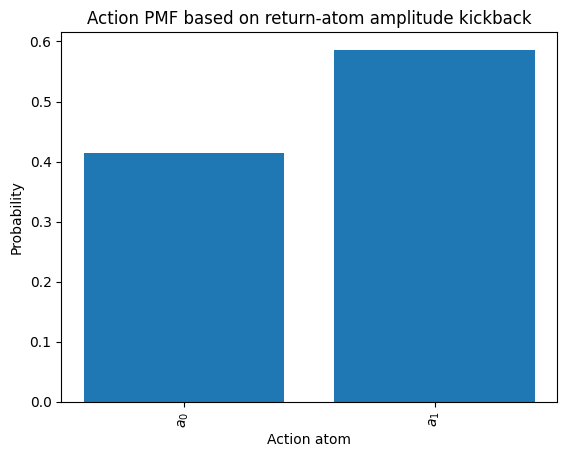

<Figure size 640x480 with 0 Axes>

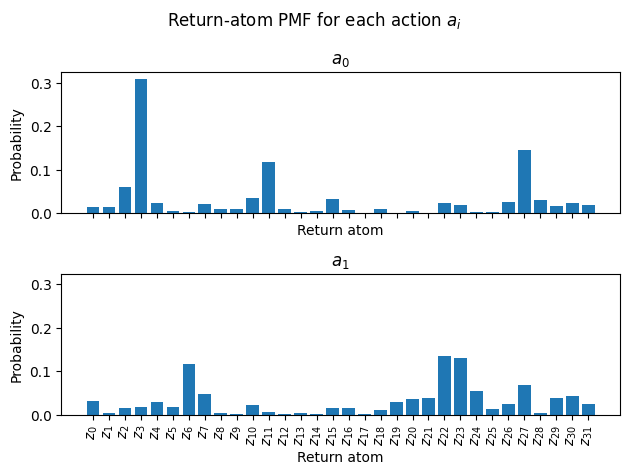

<Figure size 640x480 with 0 Axes>

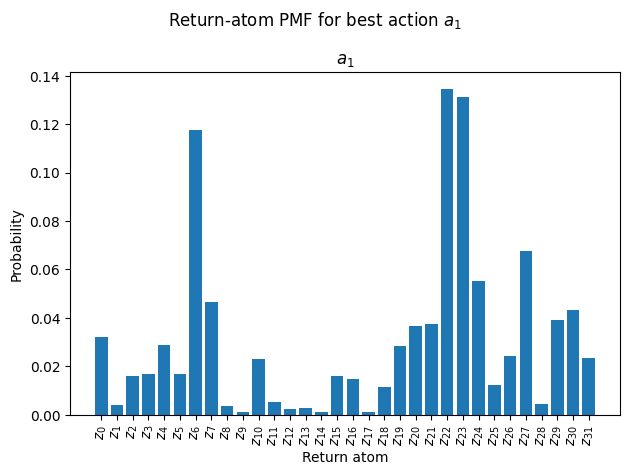

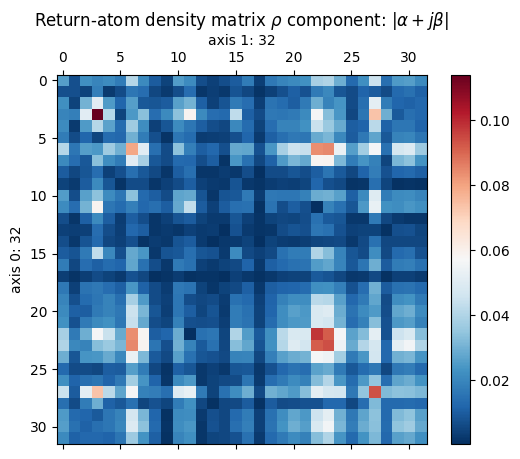

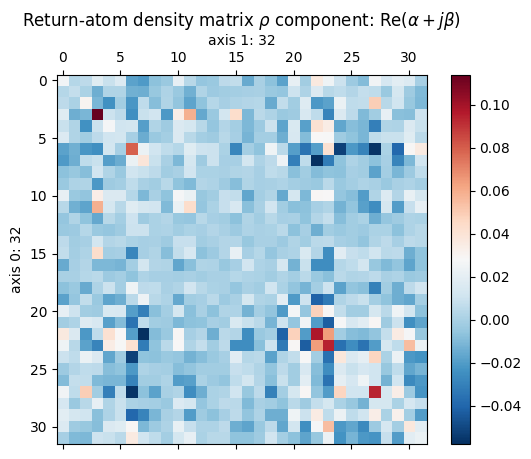

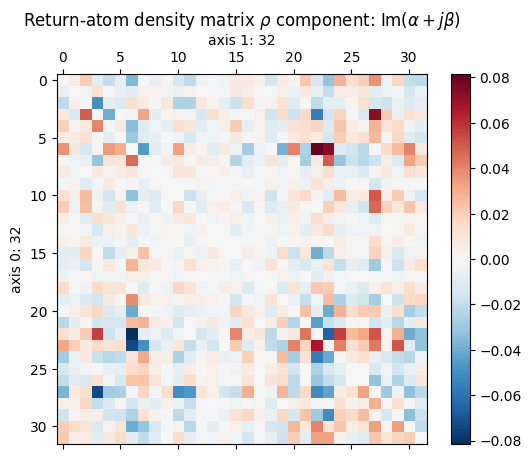

In [19]:
# Inspect density matrices before training.
# Preserve the observation that was used to compare inspect after training.
obs_inspect, figures = inspect_model_pmfs_for_env(config.env.make(), config.model)

observation_proj.shape = (1, 2, 3, 5, 1)


/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_9382/1925002666.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()




In [20]:
### Draw quantum circuit.

key = jax.random.PRNGKey(0)
# device_name = 'default.mixed'
device_name = 'default.qubit'
shots = None
diff_method = "backprop"

model = config.model
inputs = jax.random.normal(key=key, shape=(1, model.circ_observation_shape_in))
weights = model.circ_weights_var
probs_actions = jnp.ones(shape=(model.n_actions,))
n_actions = model.n_actions
d_actions = model.d_actions
d_returns = model.d_returns
n_layers = model.n_layers
pauli_enc = model.pauli_enc
pauli_var = model.pauli_var
imprimitive = model.imprimitive

device = qml.device(name=device_name, shots=shots, seed=key)
qnode = circuit_return_dist
qnode = qml.QNode(func=qnode, device=device, interface="jax", diff_method=diff_method)
qnode = qml.transforms.decompose(qnode, max_expansion=2)
# print(qml.draw(qnode, level='device')(
#     inputs=inputs,
#     # probs_actions=probs_actions,
#     probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
#     weights=weights,
#     n_actions=n_actions,
#     d_actions=d_actions,
#     d_returns=d_returns,
#     n_layers=n_layers,
# ))

observation_proj = model.project_observations(inputs)
print(f"{observation_proj.shape = }")
observation_proj = observation_proj[0] # Remove batch dimension.

circuit_string = qml.draw(qnode, level='device')(
    inputs=observation_proj,
    # probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
    probs_actions=jnp.ones(shape=(n_actions,)),
    weights=weights,
    n_actions=n_actions,
    d_actions=d_actions,
    d_returns=d_returns,
    n_layers=n_layers,
    pauli_enc=pauli_enc,
    pauli_var=pauli_var,
    imprimitive=imprimitive,
)
# print(f"{len(circuit_string) = }")
# print(circuit_string)

fig, ax = qml.draw_mpl(qnode, level='device', style='sketch', decimals=2)(
    inputs=observation_proj,
    # probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
    probs_actions=jnp.ones(shape=(n_actions,)),
    weights=weights,
    n_actions=n_actions,
    d_actions=d_actions,
    d_returns=d_returns,
    n_layers=n_layers,
    pauli_enc=pauli_enc,
    pauli_var=pauli_var,
    imprimitive=imprimitive,
)

fig.show()

# fig.savefig(f"./circuit_{cfg_hash}.pdf");

## Train

In [21]:
from qnrl.metric import LocalFileMetricManager, WandBMetricManager


do_train = True
save_metrics = True
###
metric_filepath = Path(f"./metrics/{cfg_hash}")
# metric_manager = LocalFileMetricManager(
#     metric_dir=metric_filepath.resolve(),
#     metric_file_type="json",
#     save_interval_steps=1,
#     max_to_keep=1,
#     )
###
# metric_manager = WandBMetricManager(
#     login=False, # Already logged in at beginning of notebook.
#     project="qnrl",
#     name=f"qnrl/{env_id}/{cfg_hash}",
#     config=config.to_dict(),
#     monitor_gym=False, # Causes error: "'RecordVideo' object has no attribute 'enabled'"
#     save_code=True, # Preserve notebook.
#     terminate_on_wait_until_finished=False,
#     define_metrics=[
#         {"name": "*", "summary": "min"},
#         {"name": "*", "summary": "max"},
#         {"name": "*", "summary": "mean"},
#         {"name": "*", "summary": "first"},
#         {"name": "*", "summary": "last"},
#     ],
# )

In [22]:
import warnings
warnings.simplefilter('error', category=FutureWarning)

In [23]:
# if metric_filepath.exists() and not do_train:
if not do_train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    # history_list = qnrl.tools.load_train_results(metric_filepath)
    # history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    metric_manager.load()
    history_dict = metric_manager.get_metrics()
    
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    print(f"Live plot command (episode_reward): uv run python -m qnrl.cli plot-live --x episode_step --y episode_reward --stats --history {metric_filepath}")
    print(f"Live plot command (loss): uv run python -m qnrl.cli plot-live --x loss_step --y loss --stats --history {metric_filepath}")
    
    train_history_df, train_report = config.train(
        # metric_manager=metric_manager if save_metrics else None,
    )
    
    # # Train the model.
    # history_list, buffer = config.train(
    #     return_buffer=True,
    #     metric_manager=metric_manager if save_metrics else None,
    #     )
    # history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # # Preserve training results.
    # if save_metrics:
    #     qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore-qnrl-v11.json
Hash: 15494743-184a-55ce-aedd-eda4f97acde6
History: metrics/15494743-184a-55ce-aedd-eda4f97acde6
Live plot command (episode_reward): uv run python -m qnrl.cli plot-live --x episode_step --y episode_reward --stats --history metrics/15494743-184a-55ce-aedd-eda4f97acde6
Live plot command (loss): uv run python -m qnrl.cli plot-live --x loss_step --y loss --stats --history metrics/15494743-184a-55ce-aedd-eda4f97acde6


100%|██████████| 100000/100000 [24:30<00:00, 68.00step/s, train/step=1e+5, train/episode_reward=341, train/episode_length=341, train/episode_time=5.47, train/loss=2.47, train/cross_entropy=2.47, train/kl_div=0.00327]


In [25]:
train_report

{'train/seed': 0,
 'train/total_model_parameter_count': 170,
 'train/step.mean': 49999.5,
 'train/step.std': 28867.65779668774,
 'train/step.min': 0.0,
 'train/step.max': 99999.0,
 'train/episode_reward.mean': 56.70387507229613,
 'train/episode_reward.std': 73.46908357099714,
 'train/episode_reward.min': 8.0,
 'train/episode_reward.max': 500.0,
 'train/episode_length.mean': 56.70387507229613,
 'train/episode_length.std': 73.46908357099714,
 'train/episode_length.min': 8.0,
 'train/episode_length.max': 500.0,
 'train/episode_time.mean': 0.8344817790630422,
 'train/episode_time.std': 1.249171144420261,
 'train/episode_time.min': 0.009202,
 'train/episode_time.max': 8.203819,
 'train/loss.mean': 2.8425550761497647,
 'train/loss.std': 0.13850474521096065,
 'train/loss.min': 2.4489460877507803,
 'train/loss.max': 3.646539590503931,
 'train/cross_entropy.mean': 2.8425550761497647,
 'train/cross_entropy.std': 0.13850474521096065,
 'train/cross_entropy.min': 2.4489460877507803,
 'train/cross_e

In [26]:
train_history_df

,train/step,train/epsilon,train/epsilon_greedy_threshold,train/episode_reward,train/episode_length,train/episode_time,train/loss,train/cross_entropy,train/kl_div
0,0,1.0,0.22411363313050225,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.999981,0.39708634584935965,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0.999962,0.6754005720969567,NaN,NaN,NaN,NaN,NaN,NaN
3,3,0.999943,0.825688752641744,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.999924,0.9850565082087632,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
99995,99995,0.05,0.255035751891181,NaN,NaN,NaN,NaN,NaN,NaN
99996,99996,0.05,0.4262556719554469,NaN,NaN,NaN,NaN,NaN,NaN
99997,99997,0.05,0.20679314118784653,NaN,NaN,NaN,NaN,NaN,NaN
99998,99998,0.05,0.4196201063567029,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
train_history_df.dropna(subset=['train/step', 'train/loss'])

,train/step,train/epsilon,train/epsilon_greedy_threshold,train/episode_reward,train/episode_length,train/episode_time,train/loss,train/cross_entropy,train/kl_div
10010,10010,0.80981,0.10037235119562937,NaN,NaN,NaN,3.635715,3.635715,0.680474
10020,10020,0.80962,0.46167369019215077,NaN,NaN,NaN,3.558696,3.558696,0.611733
10030,10030,0.80943,0.04963046272086169,NaN,NaN,NaN,3.646540,3.646540,0.692187
10040,10040,0.8092400000000001,0.8194909148051692,25.0,25.0,0.298071,3.569805,3.569805,0.621518
10050,10050,0.80905,0.10438889335230095,NaN,NaN,NaN,3.538966,3.538966,0.530611
...,...,...,...,...,...,...,...,...,...
99950,99950,0.05,0.6430147959443788,NaN,NaN,NaN,2.448946,2.448946,0.019817
99960,99960,0.05,0.0722330560990243,NaN,NaN,NaN,2.469573,2.469573,0.001771
99970,99970,0.05,0.1651102305589911,NaN,NaN,NaN,2.474663,2.474663,0.001898
99980,99980,0.05,0.4974075670014222,NaN,NaN,NaN,2.462065,2.462065,0.002588


In [36]:
train_history_df.set_index('train/step')

,train/epsilon,train/epsilon_greedy_threshold,train/episode_reward,train/episode_length,train/episode_time,train/loss,train/cross_entropy,train/kl_div
train/step,,,,,,,,
0,1.0,0.22411363313050225,NaN,NaN,NaN,NaN,NaN,NaN
1,0.999981,0.39708634584935965,NaN,NaN,NaN,NaN,NaN,NaN
2,0.999962,0.6754005720969567,NaN,NaN,NaN,NaN,NaN,NaN
3,0.999943,0.825688752641744,NaN,NaN,NaN,NaN,NaN,NaN
4,0.999924,0.9850565082087632,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
99995,0.05,0.255035751891181,NaN,NaN,NaN,NaN,NaN,NaN
99996,0.05,0.4262556719554469,NaN,NaN,NaN,NaN,NaN,NaN
99997,0.05,0.20679314118784653,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
train_history_df.set_index('train/step').dropna(subset=['train/loss'])

,train/epsilon,train/epsilon_greedy_threshold,train/episode_reward,train/episode_length,train/episode_time,train/loss,train/cross_entropy,train/kl_div
train/step,,,,,,,,
10010,0.80981,0.10037235119562937,NaN,NaN,NaN,3.635715,3.635715,0.680474
10020,0.80962,0.46167369019215077,NaN,NaN,NaN,3.558696,3.558696,0.611733
10030,0.80943,0.04963046272086169,NaN,NaN,NaN,3.646540,3.646540,0.692187
10040,0.8092400000000001,0.8194909148051692,25.0,25.0,0.298071,3.569805,3.569805,0.621518
10050,0.80905,0.10438889335230095,NaN,NaN,NaN,3.538966,3.538966,0.530611
...,...,...,...,...,...,...,...,...
99950,0.05,0.6430147959443788,NaN,NaN,NaN,2.448946,2.448946,0.019817
99960,0.05,0.0722330560990243,NaN,NaN,NaN,2.469573,2.469573,0.001771
99970,0.05,0.1651102305589911,NaN,NaN,NaN,2.474663,2.474663,0.001898


In [46]:
train_history_df.set_index('train/step').dropna(subset=['train/loss', 'train/epsilon'])[['train/loss', 'train/epsilon']]

,train/loss,train/epsilon
train/step,,
10010,3.635715,0.80981
10020,3.558696,0.80962
10030,3.646540,0.80943
10040,3.569805,0.8092400000000001
10050,3.538966,0.80905
...,...,...
99950,2.448946,0.05
99960,2.469573,0.05
99970,2.474663,0.05


In [50]:
train_history_df.set_index('train/step')[['train/loss', 'train/epsilon']].dropna()

,train/loss,train/epsilon
train/step,,
10010,3.635715,0.80981
10020,3.558696,0.80962
10030,3.646540,0.80943
10040,3.569805,0.8092400000000001
10050,3.538966,0.80905
...,...,...
99950,2.448946,0.05
99960,2.469573,0.05
99970,2.474663,0.05


In [ ]:
l = (1,23)
type(l)()

AttributeError: 'tuple' object has no attribute 'append'

<Axes: xlabel='train/step'>

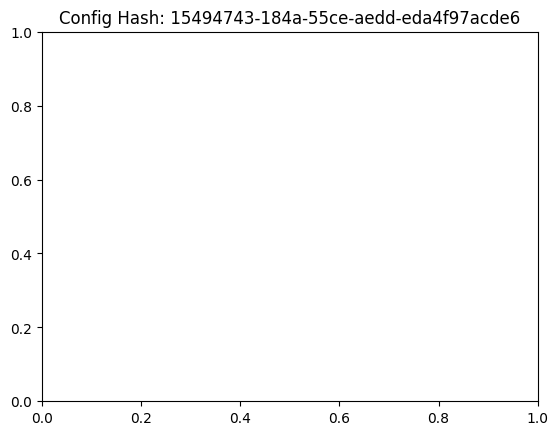

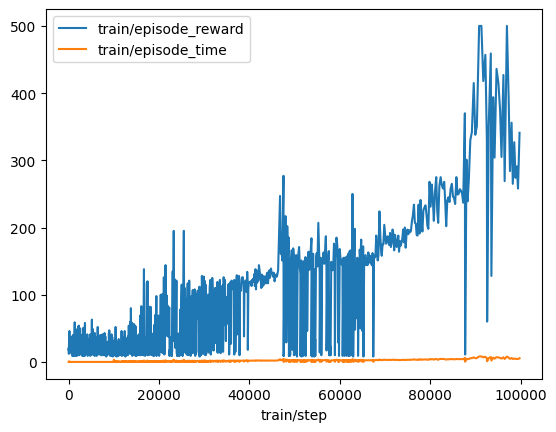

In [54]:
import matplotlib.pyplot as plt

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))
# metric_manager.load()
# history_dict = metric_manager.get_dataframe()

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
# plt.plot(history_dict['train/step'].dropna(), history_dict['train/loss'].dropna())
# plt.plot(train_history_df.dropna(subset=['train/step', 'train/loss']))
# train_history_df.set_index('train/step')[['train/loss', 'train/epsilon']].dropna().plot(kind="line")
train_history_df.set_index('train/step')[['train/episode_reward', 'train/episode_time']].dropna().plot(kind="line")
# plt.xlabel('Step')
# plt.ylabel('loss')

# plt.figure()
# plt.title(f"Config Hash: {cfg_hash}")
# plt.plot(history_dict['train/metric_step'].dropna(), history_dict['train/cross_entropy'].dropna())
# plt.xlabel('Step')
# plt.ylabel('cross_entropy')

# plt.figure()
# plt.title(f"Config Hash: {cfg_hash}")
# plt.plot(history_dict['train/metric_step'].dropna(), history_dict['train/kl_div'].dropna())
# plt.xlabel('Step')
# plt.ylabel('kl_div')

# plt.figure()
# plt.title(f"Config Hash: {cfg_hash}")
# plt.plot(history_dict['train/episode_step'].dropna(), history_dict['train/episode_reward'].dropna())
# plt.xlabel('Step')
# plt.ylabel('episode_reward')

In [ ]:
# # Plot loss and episode reward on the same plot.

# # history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))
# metric_manager.load()
# history_dict = metric_manager.get_metrics()

# fig, axs = plt.subplots(4,1, sharex=True, figsize=(10,8))
# axs = axs.squeeze()

# axs[0].set_title(f"Config Hash: {cfg_hash}")
# plt.xlabel('step')

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['loss_step']) >= config.learning_starts
# history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
# history_dict['loss'] = np.array(history_dict['loss'])[idx]

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['metric_step']) >= config.learning_starts
# history_dict['metric_step'] = np.array(history_dict['metric_step'])[idx]
# history_dict['cross_entropy'] = np.array(history_dict['cross_entropy'])[idx]

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['metric_step']) >= config.learning_starts
# history_dict['metric_step'] = np.array(history_dict['metric_step'])[idx]
# history_dict['kl_div'] = np.array(history_dict['kl_div'])[idx]

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['episode_step']) >= config.learning_starts
# history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
# history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

# axs[0].plot(history_dict['loss_step'], history_dict['loss'])
# axs[0].set_ylabel('loss')
# axs[0].grid() # Turn on a grid.

# axs[1].plot(history_dict['metric_step'], history_dict['cross_entropy'])
# axs[1].set_ylabel('cross_entropy')
# axs[1].grid() # Turn on a grid.

# axs[2].plot(history_dict['metric_step'], history_dict['kl_div'])
# axs[2].set_ylabel('kl_div')
# axs[2].grid() # Turn on a grid.

# axs[-1].plot(history_dict['episode_step'], history_dict['episode_reward'])
# axs[-1].set_ylabel('episode_reward')
# axs[-1].grid() # Turn on a grid.

# # Save the figure file.
# figfile = f"./figures/{cfg_hash}.pdf"
# fig.savefig(figfile)
# print(figfile)

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 15c2addf0, raw_cell="# Inspect the model again using the same observati.." transformed_cell="# Inspect the model again using the same observati.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X41sZmlsZQ%3D%3D>,),kwargs {}:


MailboxClosedError: 

P(a0): 0.07171538205677153
Q(a0): 335.3998920673277
P(a1): 0.07232351601935483
Q(a1): 338.24402479817536
P(a2): 0.0724695556489665
Q(a2): 338.92702577515564
P(a3): 0.07219436072518871
Q(a3): 337.6399888092304
P(a4): 0.07094144127936974
Q(a4): 331.78031080369306
P(a5): 0.07012035097238968
Q(a5): 327.94021970412103
P(a6): 0.0674967776194252
Q(a6): 315.6702408770063
P(a7): 0.07233375591797472
Q(a7): 338.291914954978
P(a8): 0.07245239373210934
Q(a8): 338.8467625889815
P(a9): 0.0690873301771403
Q(a9): 323.1089679796903
P(a10): 0.07114971307594217
Q(a10): 332.7543603881431
P(a11): 0.07284090950928504
Q(a11): 340.6637807236411
P(a12): 0.07247339167223932
Q(a12): 338.9449661633228
P(a13): 0.0724011215938431
Q(a13): 338.6069720566397
observations = Array([[169, 106, 249, 207, 145, 231,  38, 184, 181, 199, 194,  65,  56,
        193, 230, 189, 174, 198, 248,  86, 254,  15,  64,  76, 121,  93,
        247,  51, 149, 248,   8, 184, 194, 157,  33, 105,   8,  90,  86,
         18,  72, 219, 138, 113

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_16539/4289682592.py:108: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


best_action.item() = 11
best_return_pmf == return_pmfs[best_action.item()] = Array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True], dtype=bool)


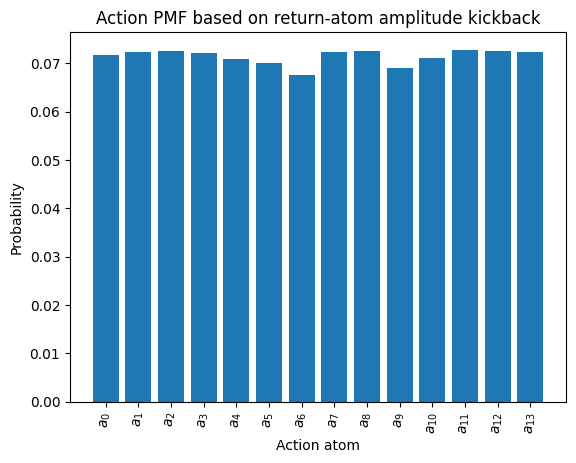

<Figure size 640x480 with 0 Axes>

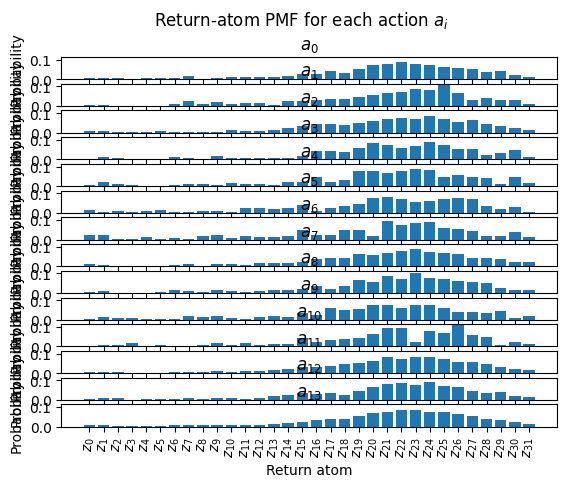

<Figure size 640x480 with 0 Axes>

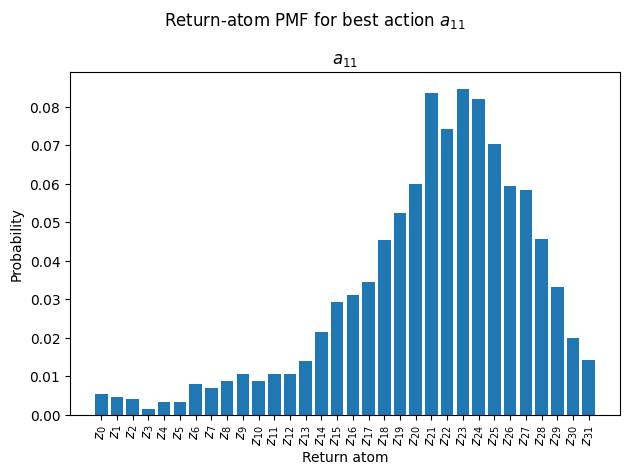

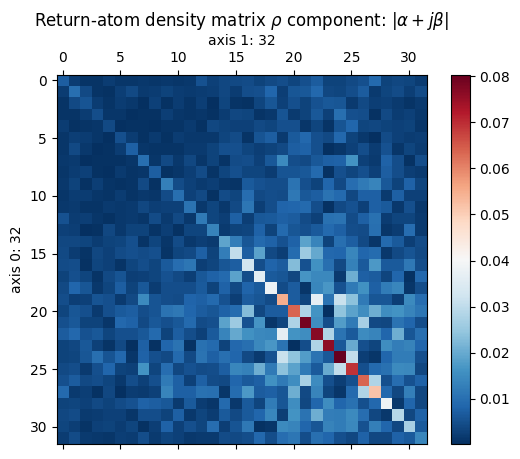

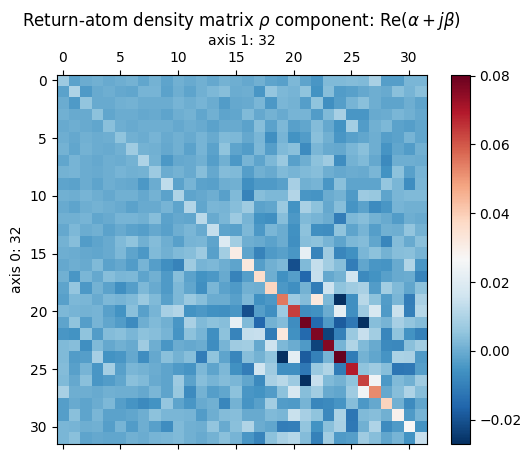

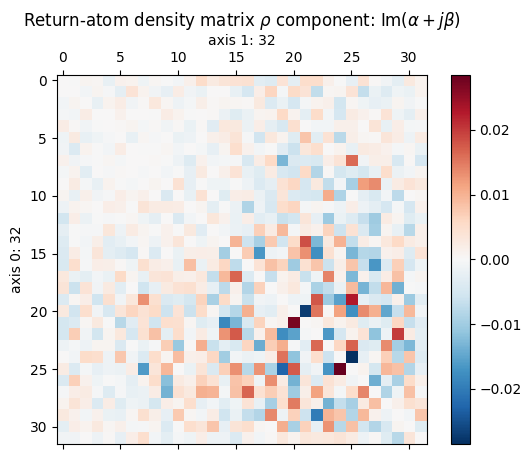

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for post_run_cell), with arguments args (<ExecutionResult object at 155f656a0, execution_count=24 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 15c2addf0, raw_cell="# Inspect the model again using the same observati.." transformed_cell="# Inspect the model again using the same observati.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X41sZmlsZQ%3D%3D> result=None>,),kwargs {}:


BrokenPipeError: [Errno 32] Broken pipe

In [ ]:
# Inspect the model again using the same observation used prior to training.
figures = inspect_model_pmfs_for_observation(obs_inspect, config.model)

metric_manager.run.log({"inspect_model_pmfs_for_observation": [wandb.Image(f) for f in figures], "observation": obs_inspect})

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 15ef3f590, raw_cell="# Inspect the model for an initial observation upo.." transformed_cell="# Inspect the model for an initial observation upo.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X42sZmlsZQ%3D%3D>,),kwargs {}:


MailboxClosedError: 

P(a0): 0.06482665957933377
Q(a0): 297.74972678376395
P(a1): 0.07167110553103882
Q(a1): 329.18635988086857
P(a2): 0.0719252969667299
Q(a2): 330.35386459295614
P(a3): 0.06719637841890932
Q(a3): 308.6338775577906
P(a4): 0.07198431761389719
Q(a4): 330.6249472259763
P(a5): 0.07055990503833091
Q(a5): 324.0826009450734
P(a6): 0.07181936257534717
Q(a6): 329.8673064963966
P(a7): 0.07403541963894816
Q(a7): 340.04568664903985
P(a8): 0.07386831814297032
Q(a8): 339.2781872113793
P(a9): 0.0736300294326368
Q(a9): 338.1837239325697
P(a10): 0.07160529380553508
Q(a10): 328.88408573293185
P(a11): 0.0698166451185931
Q(a11): 320.6687980518297
P(a12): 0.073630449330852
Q(a12): 338.18565253076775
P(a13): 0.07343081880687734
Q(a13): 337.2687468262808
observations = Array([[  0,   4,  96,   1,  63, 224,   0,   0,   0,   0,   0,   0,   1,
         63, 224,   0,   0,   0,   0,   0,   0,  71, 135,   0,   0,   0,
          0,   0,   0,   0,  22,  54,   0,   0,   0,   0,   0,   0,   0,
         12,  24,   0,   0,  

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_16539/4289682592.py:108: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


best_action.item() = 7
best_return_pmf == return_pmfs[best_action.item()] = Array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True], dtype=bool)


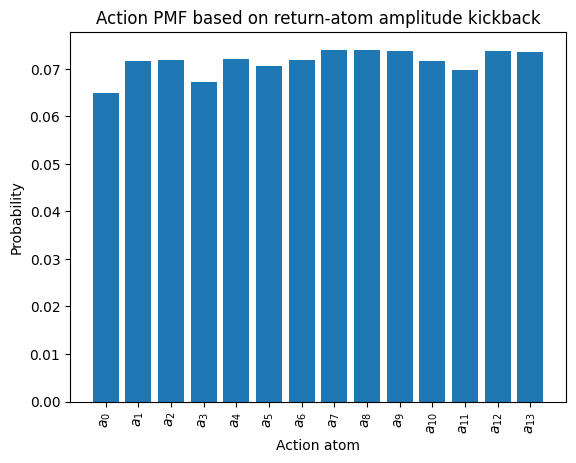

<Figure size 640x480 with 0 Axes>

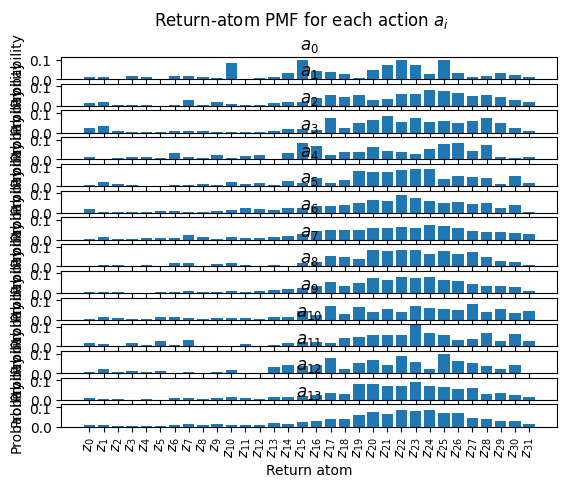

<Figure size 640x480 with 0 Axes>

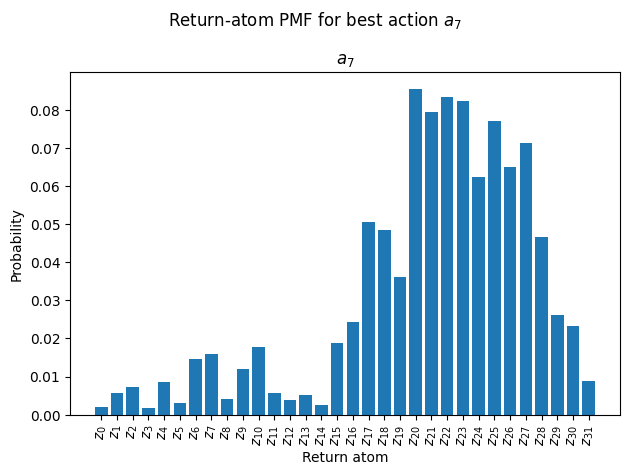

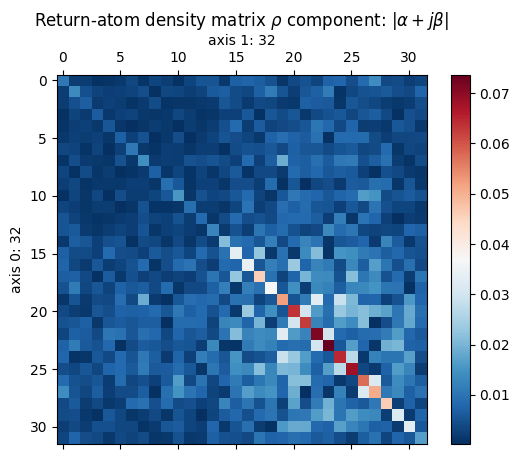

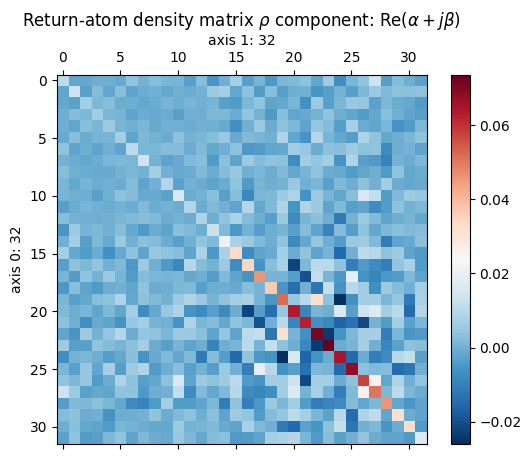

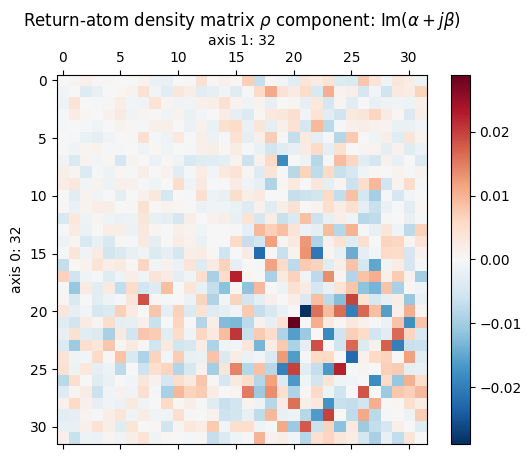

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for post_run_cell), with arguments args (<ExecutionResult object at 15ef3c6b0, execution_count=25 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 15ef3f590, raw_cell="# Inspect the model for an initial observation upo.." transformed_cell="# Inspect the model for an initial observation upo.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X42sZmlsZQ%3D%3D> result=None>,),kwargs {}:


BrokenPipeError: [Errno 32] Broken pipe

In [ ]:
# Inspect the model for an initial observation upon first reset.
obs = config.env.make().reset()[0]
figures = inspect_model_pmfs_for_observation(obs, config.model)

metric_manager.run.log({"inspect_model_pmfs_for_observation": [wandb.Image(f) for f in figures], "observation": obs})

In [26]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 1650e5f70, raw_cell="# Print all the parameters.
nnx.state(config.model.." transformed_cell="# Print all the parameters.
nnx.state(config.model.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X43sZmlsZQ%3D%3D>,),kwargs {}:


MailboxClosedError: 

State({
  'circ_weights_enc_obs_kernel': Param( # 350 (2.8 KB)
    value=Array([[[[ 0.39410313],
             [ 0.33387481],
             [ 1.00408056],
             [ 1.25412716],
             [ 1.23874668]],
    
            [[ 1.26654901],
             [ 0.47209831],
             [ 1.13925772],
             [ 0.5849945 ],
             [ 1.09160819]],
    
            [[ 1.2725515 ],
             [ 1.44585912],
             [ 1.1228677 ],
             [ 1.40680657],
             [ 0.20882297]],
    
            [[ 0.97189628],
             [ 1.2730045 ],
             [ 0.94773019],
             [ 0.60672904],
             [ 0.93890769]],
    
            [[ 0.87946798],
             [ 1.01428941],
             [ 1.18860781],
             [ 0.91501263],
             [ 1.284932  ]]],
    
    
           [[[ 1.31882919],
             [ 0.63287721],
             [ 0.22716908],
             [ 0.95179688],
             [ 1.49856339]],
    
            [[ 0.92010683],
             [ 0.3733

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for post_run_cell), with arguments args (<ExecutionResult object at 1650e78c0, execution_count=26 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 1650e5f70, raw_cell="# Print all the parameters.
nnx.state(config.model.." transformed_cell="# Print all the parameters.
nnx.state(config.model.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X43sZmlsZQ%3D%3D> result=State({
  'circ_weights_enc_obs_kernel': Param( # 350 (2.8 KB)
    value=Array([[[[ 0.39410313],
             [ 0.33387481],
             [ 1.00408056],
             [ 1.25412716],
             [ 1.23874668]],
    
            [[ 1.26654901],
             [ 0.47209831],
             [ 1.13925772],
             [ 0.5849945 ],
             [ 1.09160819]],
    
            [[ 1.2725515 ],
             

BrokenPipeError: [Errno 32] Broken pipe

## Evaluate

In [27]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 1652210d0, raw_cell="eval_metric_list = config.eval()
eval_metric_dict .." transformed_cell="eval_metric_list = config.eval()
eval_metric_dict .." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X45sZmlsZQ%3D%3D>,),kwargs {}:


MailboxClosedError: 

  1%|          | 786/100000 [00:14<29:45, 55.57step/s, eval/episode_step=786, eval/episode_reward=1180.0, eval/episode_length=787, eval/episode_time=14.1]


eval/episode_step: 786
eval/episode_reward: 1180.0
eval/episode_length: 787
eval/episode_time: 14.144677
Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for post_run_cell), with arguments args (<ExecutionResult object at 165223770, execution_count=27 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 1652210d0, raw_cell="eval_metric_list = config.eval()
eval_metric_dict .." transformed_cell="eval_metric_list = config.eval()
eval_metric_dict .." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X45sZmlsZQ%3D%3D> result=None>,),kwargs {}:


BrokenPipeError: [Errno 32] Broken pipe

In [ ]:
# inspect_model_pmfs_for_observation(jnp.array([-0.01053775,  0.03950866, -0.03218421, -0.04678081]), config.model)

## Evaluate across multiple runs

In [ ]:
# Evaluate multiple times and preserve results.
# n_runs = 10
# n_runs = 50
n_runs = 100
# n_runs = 1000
eval_metric_dict_runs = []
key = jax.random.PRNGKey(seed=config.seed)

log_keys = ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',)
for r in range(n_runs):
    
    # Generate a new random key.
    key, subkey = jax.random.split(key=key)
    
    # Evaluate the model within environment seeded from random subkey.
    seed_eval = int(subkey[0])
    eval_metric_list = config.eval(seed=seed_eval)
    eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
    eval_metric_dict['eval/seed'] = [seed_eval]
    eval_metric_dict_runs.append(eval_metric_dict)
    
    # d = {k: v[0] for k, v in eval_metric_dict.items() if k in log_keys}
    d = {k: eval_metric_dict[k][0] for k in log_keys}
    metric_manager.run.log(d)

# Report statistics across all runs.
for key in log_keys:
    l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
    print(f"{key}: min: {jnp.min(l)}")
    print(f"{key}: max: {jnp.max(l)}")
    print(f"{key}: mean: {jnp.mean(l)}")
    print(f"{key}: std: {jnp.std(l)}")

  0%|          | 499/100000 [00:01<05:20, 310.70step/s, eval/episode_step=499, eval/episode_reward=-500, eval/episode_length=500, eval/episode_time=1.61]


eval/episode_step: min: 499
eval/episode_step: max: 499
eval/episode_step: mean: 499.0
eval/episode_step: std: 0.0
eval/episode_reward: min: -500.0
eval/episode_reward: max: -500.0
eval/episode_reward: mean: -500.0
eval/episode_reward: std: 0.0
eval/episode_length: min: 500
eval/episode_length: max: 500
eval/episode_length: mean: 500.0
eval/episode_length: std: 0.0
eval/episode_time: min: 1.604264
eval/episode_time: max: 1.880704
eval/episode_time: mean: 1.6782089900000003
eval/episode_time: std: 0.04586297102619823


## Record a run as a video

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 165430e00, raw_cell="import os
import tempfile
from IPython.display imp.." transformed_cell="import os
import tempfile
from IPython.display imp.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X53sZmlsZQ%3D%3D>,),kwargs {}:


MailboxClosedError: 

/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp6z5w0dej folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


tmpdir = '/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp6z5w0dej'


  1%|          | 622/100000 [00:11<29:45, 55.65step/s, eval/episode_step=622, eval/episode_reward=480, eval/episode_length=623, eval/episode_time=11.2]


eval/episode_step: min: 622
eval/episode_step: max: 622
eval/episode_step: mean: 622.0
eval/episode_step: std: 0.0
eval/episode_reward: min: 480.0
eval/episode_reward: max: 480.0
eval/episode_reward: mean: 480.0
eval/episode_reward: std: 0.0
eval/episode_length: min: 623
eval/episode_length: max: 623
eval/episode_length: mean: 623.0
eval/episode_length: std: 0.0
eval/episode_time: min: 11.177575
eval/episode_time: max: 11.177575
eval/episode_time: mean: 11.177575
eval/episode_time: std: 0.0
os.listdir(tmpdir) = ['rl-video-episode-0.mp4']
MoviePy - Building file /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp6z5w0dej/rl-video-episode-0.gif with imageio.


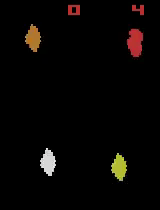

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for post_run_cell), with arguments args (<ExecutionResult object at 165430cb0, execution_count=28 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 165430e00, raw_cell="import os
import tempfile
from IPython.display imp.." transformed_cell="import os
import tempfile
from IPython.display imp.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X53sZmlsZQ%3D%3D> result=None>,),kwargs {}:


BrokenPipeError: [Errno 32] Broken pipe

In [28]:
import os
import tempfile
from IPython.display import display, Video, Image
from moviepy import VideoFileClip

with tempfile.TemporaryDirectory() as tmpdir:
    print(f"{tmpdir = }")

    # Create wrapper for recording video.
    env_wrappers = [
        lambda env: gym.wrappers.RecordVideo(env, video_folder=tmpdir, episode_trigger=lambda x: True, disable_logger=True),
    ]
    
    # Evaluate multiple times and preserve results.
    n_runs = 1
    eval_metric_dict_runs = []
    key = jax.random.PRNGKey(seed=1423)
    for r in range(n_runs):
        
        # Generate a new random key.
        key, subkey = jax.random.split(key=key)
        
        # Evaluate the model within environment seeded from random subkey.
        eval_metric_list = config.eval(seed=int(subkey[0]), env=config.env.make(render_mode='rgb_array'), model_policy=config.model, total_timesteps=config.total_timesteps, env_wrappers=env_wrappers)
        eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
        eval_metric_dict['eval/seed'] = int(subkey[0])
        eval_metric_dict_runs.append(eval_metric_dict)

    # Report statistics across all runs.
    for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
        l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
        print(f"{key}: min: {jnp.min(l)}")
        print(f"{key}: max: {jnp.max(l )}")
        print(f"{key}: mean: {jnp.mean(l)}")
        print(f"{key}: std: {jnp.std(l)}")
    
    print(f"{os.listdir(tmpdir) = }")
    
    videofilepath = Path(tmpdir)/os.listdir(tmpdir)[0]
    
    # Build a GIF from the video file.
    giffilepath = Path(tmpdir)/(videofilepath.stem + '.gif')
    clip = VideoFileClip(videofilepath)
    clip.write_gif(giffilepath, fps=15)
    
    # display(Video(videofilepath, embed=True, html_attributes="controls muted loop autoplay"))
    display(Image(filename=giffilepath))

In [ ]:
metric_manager.run.finish()

eval/episode_length,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/episode_reward,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/episode_step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/episode_time,▁▁█▅▅▅▄▄▄▃▄▃▄▃▃▄▃▃▄▃▃▄▅▅▃▄▃▄▃▄▄▄▃▃▃▅▆▃▄▂
train/cross_entropy,███▇▇▇▇▇▇▆▆▅▄▄▄▃▂▂▂▂▃▂▁▆▁▅▅▃▇▇▄▃▄▄▃▄▄▄▄▄
train/episode_length,██████▂████████████████▃█▃▅██▁█▂██▅▃▇███
train/episode_reward,▁▁▁█▁▁▁▁▄▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▇▄▂▁█▄▄▁▂▁
train/episode_step,▁▁▁▂▂▂▂▂▂▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇████
train/episode_time,▁▁▁▁█████▅███████▇██████▆█▄█▇▅██▄█▇▇▅█▅█
train/kl_div,▂▂▁▁▁▁▁▁▁▇▁▁▆▁▁▁▁█▁▁▂▁▁▁▁▁▂▁▁▂▁▂▁▁▁▁▁▁▁▁
+3,...


In [29]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 15f15a900, raw_cell="# Print all the parameters.
nnx.state(config.model.." transformed_cell="# Print all the parameters.
nnx.state(config.model.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X55sZmlsZQ%3D%3D>,),kwargs {}:


MailboxClosedError: 

State({
  'circ_weights_enc_obs_kernel': Param( # 350 (2.8 KB)
    value=Array([[[[ 0.39410313],
             [ 0.33387481],
             [ 1.00408056],
             [ 1.25412716],
             [ 1.23874668]],
    
            [[ 1.26654901],
             [ 0.47209831],
             [ 1.13925772],
             [ 0.5849945 ],
             [ 1.09160819]],
    
            [[ 1.2725515 ],
             [ 1.44585912],
             [ 1.1228677 ],
             [ 1.40680657],
             [ 0.20882297]],
    
            [[ 0.97189628],
             [ 1.2730045 ],
             [ 0.94773019],
             [ 0.60672904],
             [ 0.93890769]],
    
            [[ 0.87946798],
             [ 1.01428941],
             [ 1.18860781],
             [ 0.91501263],
             [ 1.284932  ]]],
    
    
           [[[ 1.31882919],
             [ 0.63287721],
             [ 0.22716908],
             [ 0.95179688],
             [ 1.49856339]],
    
            [[ 0.92010683],
             [ 0.3733

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x147b56870>> (for post_run_cell), with arguments args (<ExecutionResult object at 15f15a0c0, execution_count=29 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 15f15a900, raw_cell="# Print all the parameters.
nnx.state(config.model.." transformed_cell="# Print all the parameters.
nnx.state(config.model.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/derieux/research/qnrl/sandbox-qnrl-v11.ipynb#X55sZmlsZQ%3D%3D> result=State({
  'circ_weights_enc_obs_kernel': Param( # 350 (2.8 KB)
    value=Array([[[[ 0.39410313],
             [ 0.33387481],
             [ 1.00408056],
             [ 1.25412716],
             [ 1.23874668]],
    
            [[ 1.26654901],
             [ 0.47209831],
             [ 1.13925772],
             [ 0.5849945 ],
             [ 1.09160819]],
    
            [[ 1.2725515 ],
             

BrokenPipeError: [Errno 32] Broken pipe